In [1]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import xgboost as xgb
import numpy as np
import utils
import seaborn as sns


from utils import (
    calculate_technical_indicators,
    compare_results,
    evaluate_predictions,
    evaluate_torch_model,
    fit_arima,
    fit_standard_scaler,
    forecast_arima,
    grid_search_arima,
    load_fred_data,
    normalize_to_tensor,
    plot_dataset,
    plot_predictions_vs_targets,
    predict_and_store_log_return_model,
    predict_moving_average,
    predict_naive,
    prepare_data,
    split_data,
    store_model_prediction,
    train_torch_model,
    train_xgboost,
)

DATA_DIR = Path("FRED")
RESULTS_PATH = Path("model_results.json")
TARGET_COLUMN = "INR"
FEATURE_COLUMNS = ["JPY", "EUR", "FFER", "US10YY"]
TRAIN_FRACTION = 0.8
VALIDATION_FRACTION = 0.1
EPOCHS = 100
BATCH_SIZE = 32
model_results = {}

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")

Using device: cuda


In [2]:
full_df = prepare_data(load_fred_data(DATA_DIR))
full_df["TARGET_NEXT"] = full_df[TARGET_COLUMN].shift(-1)
full_df = full_df.dropna(subset=["TARGET_NEXT"])

train_df, val_df, test_df = split_data(
    full_df,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
)

full_df.head()

,INR,JPY,EUR,FFER,US10YY,TARGET_NEXT
observation_date,,,,,,
1999-01-04,42.60,112.15,1.1812,5.04,4.69,42.56
1999-01-05,42.56,111.15,1.1760,4.54,4.74,42.55
1999-01-06,42.55,112.78,1.1636,4.23,4.73,42.55
1999-01-07,42.55,111.69,1.1672,4.49,4.77,42.55
1999-01-08,42.55,111.52,1.1554,4.74,4.86,42.55


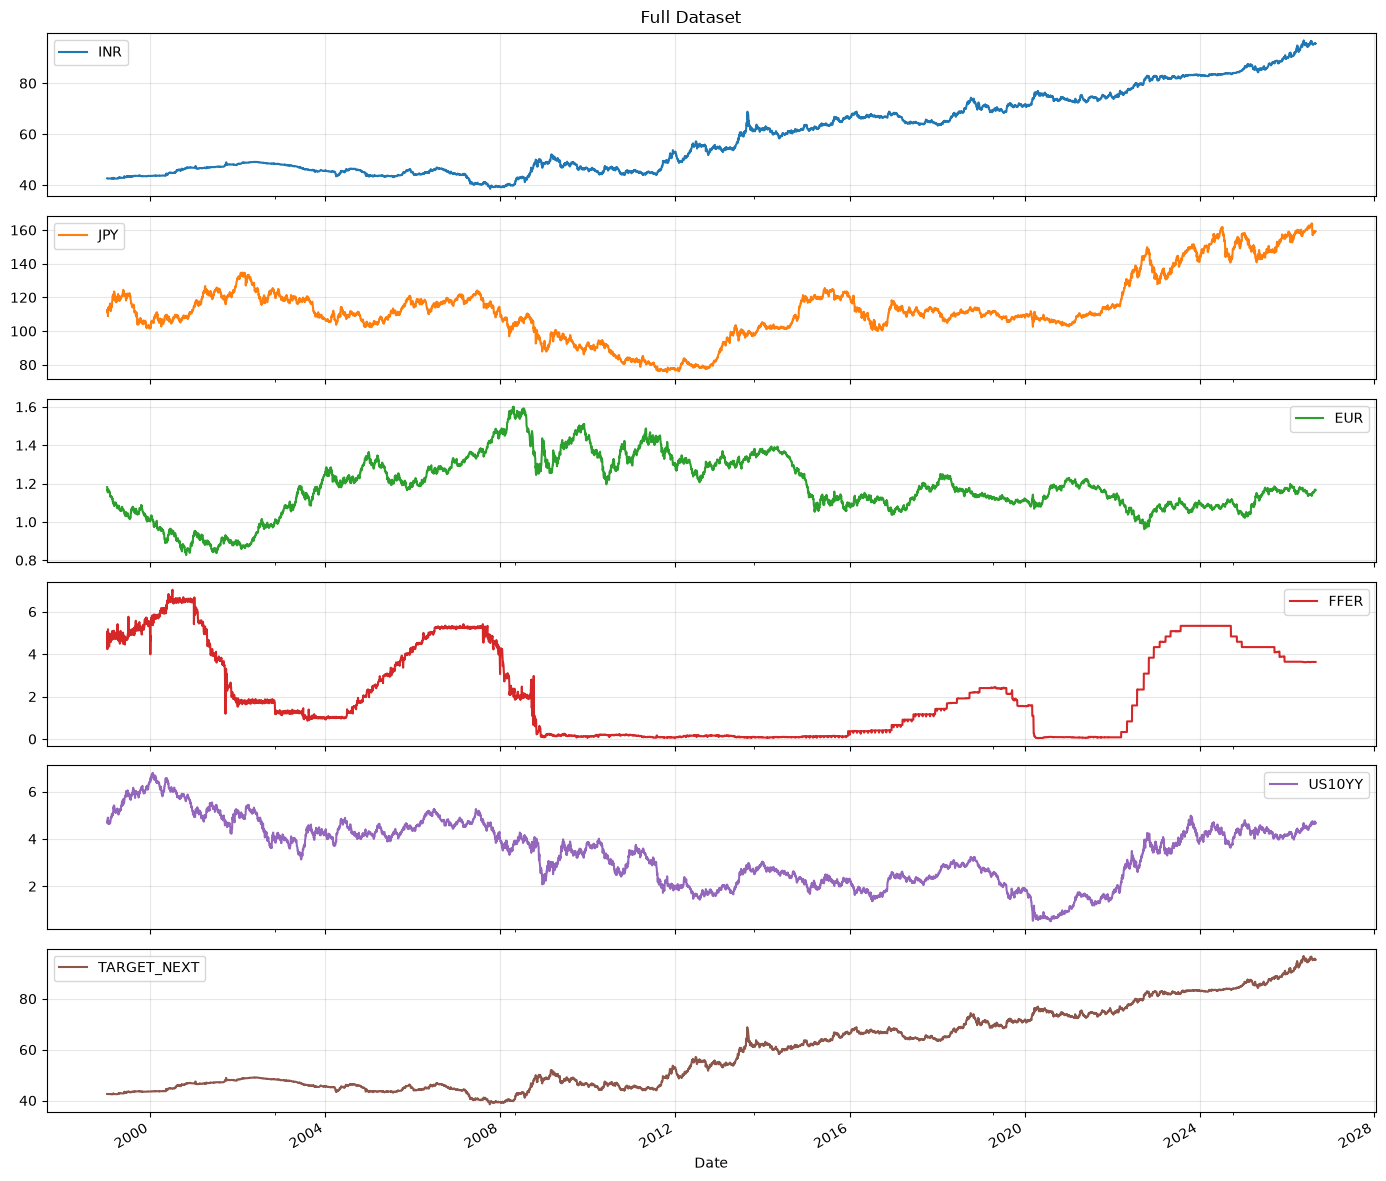

Train: (5524, 6), validation: (690, 6), test: (691, 6)


In [3]:
plot_dataset(full_df)
print(f"Train: {train_df.shape}, validation: {val_df.shape}, test: {test_df.shape}")

## Baseline and ARIMA

Naive: {'mae': 0.1493805826271353, 'mse': 0.07776622105608079, 'rmse': 0.27886595535504294, 'directional_accuracy': 53.08709034944776, 'correct_days': 2932, 'total_days': 5523}
Moving average: {'mae': 0.11185312760039676, 'mse': 0.07249965294511787, 'rmse': 0.2692575958912169, 'directional_accuracy': 78.20025348542458, 'correct_days': 4319, 'total_days': 5523}


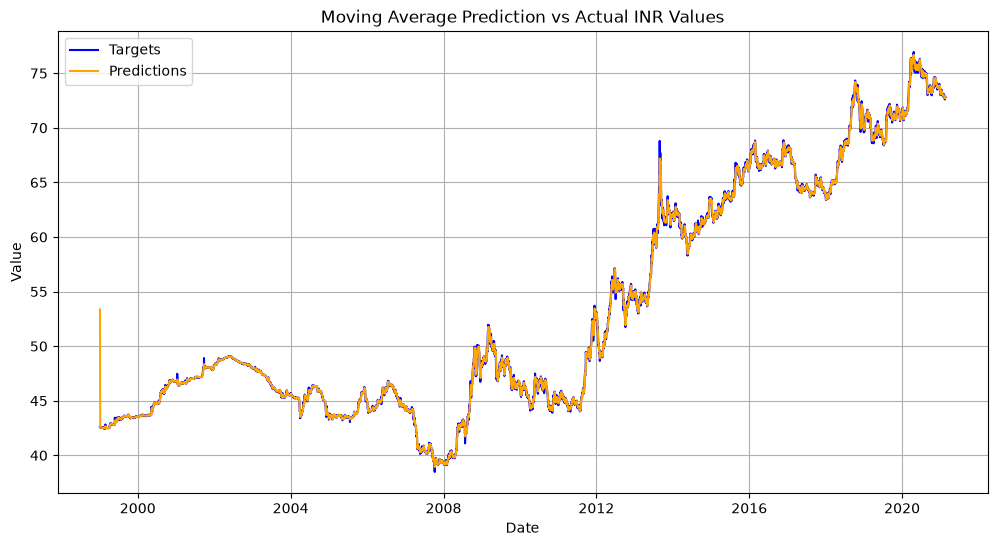

In [4]:
naive_predictions = predict_naive(train_df, TARGET_COLUMN)
moving_average_predictions = predict_moving_average(train_df, target_column=TARGET_COLUMN)

naive_metrics = evaluate_predictions(naive_predictions, train_df[TARGET_COLUMN])
moving_average_metrics = evaluate_predictions(
    moving_average_predictions,
    train_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "Naive",
    naive_predictions,
    naive_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Moving Average",
    moving_average_predictions,
    moving_average_metrics,
    "train",
)
print("Naive:", naive_metrics)
print("Moving average:", moving_average_metrics)
plot_predictions_vs_targets(
    moving_average_predictions,
    train_df[TARGET_COLUMN],
    x_values=train_df.index,
    title="Moving Average Prediction vs Actual INR Values",
)

### LINEAR MODEL

In [7]:
baseline_feature_columns = FEATURE_COLUMNS + [TARGET_COLUMN]
X_train = torch.tensor(
    train_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_train = torch.tensor(
    train_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)
X_val = torch.tensor(
    val_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_val = torch.tensor(
    val_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)
X_test = torch.tensor(
    test_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_test = torch.tensor(
    test_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

linear_model = nn.Linear(NUM_INPUT_FEATURES, OUTPUT_FEATURES)
linear_optimizer = optim.Adam(linear_model.parameters(), lr=0.01)
linear_losses = train_torch_model(
    linear_model,
    linear_optimizer,
    nn.MSELoss(),
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

deep_model = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, OUTPUT_FEATURES),
)
deep_optimizer = optim.Adam(deep_model.parameters(), lr=0.01)
deep_losses = train_torch_model(
    deep_model,
    deep_optimizer,
    nn.MSELoss(),
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

with torch.no_grad():
    linear_train_predictions = linear_model(X_train)
    linear_test_predictions = linear_model(X_test)
    deep_train_predictions = deep_model(X_train)
    deep_test_predictions = deep_model(X_test)

linear_train_metrics = evaluate_predictions(linear_train_predictions, y_train)
linear_metrics = evaluate_predictions(linear_test_predictions, y_test)
deep_train_metrics = evaluate_predictions(deep_train_predictions, y_train)
deep_metrics = evaluate_predictions(deep_test_predictions, y_test)

store_model_prediction(
    model_results,
    "Linear Regression",
    linear_train_predictions,
    linear_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Linear Regression",
    linear_test_predictions,
    linear_metrics,
    "test",
)
store_model_prediction(
    model_results,
    "Deep Learning",
    deep_train_predictions,
    deep_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Deep Learning",
    deep_test_predictions,
    deep_metrics,
    "test",
)

print(f"Linear Regression test metrics: {linear_metrics}")
print(f"Deep Learning test metrics: {deep_metrics}")

Epoch 10/100, Train Loss: 1350.4692, Val Loss: 2995.5684
Epoch 20/100, Train Loss: 507.5302, Val Loss: 1275.1062
Epoch 30/100, Train Loss: 171.2330, Val Loss: 442.0837
Epoch 40/100, Train Loss: 109.2549, Val Loss: 153.1626
Epoch 50/100, Train Loss: 114.1111, Val Loss: 86.8542
Epoch 60/100, Train Loss: 109.7742, Val Loss: 91.6828
Epoch 70/100, Train Loss: 100.8657, Val Loss: 121.0688
Epoch 80/100, Train Loss: 95.6888, Val Loss: 147.2787
Epoch 90/100, Train Loss: 92.1840, Val Loss: 154.6540
Epoch 100/100, Train Loss: 88.4353, Val Loss: 147.0493
Epoch 10/100, Train Loss: 273.4344, Val Loss: 24.1881
Epoch 20/100, Train Loss: 143.7228, Val Loss: 309.4547
Epoch 30/100, Train Loss: 69.6039, Val Loss: 80.3930
Epoch 40/100, Train Loss: 48.9685, Val Loss: 23.9417
Epoch 50/100, Train Loss: 21.5727, Val Loss: 19.9070
Epoch 60/100, Train Loss: 5.8685, Val Loss: 7.9313
Epoch 70/100, Train Loss: 1.1724, Val Loss: 1.5787
Epoch 80/100, Train Loss: 1.8234, Val Loss: 1.9869
Epoch 90/100, Train Loss: 0.88

## Technical indicators

In [8]:
technical_data = calculate_technical_indicators(full_df).dropna()
technical_data["TARGET_NEXT"] = technical_data["Log_Returns"].shift(-1)
technical_data = technical_data.dropna(subset=["TARGET_NEXT"])
technical_data.head()

,INR,JPY,EUR,FFER,US10YY,TARGET_NEXT,MA_5,MA_10,MA_30,MA_50,...,EMA_50,EMA_100,RSI,BB_Middle,BB_Upper,BB_Lower,Volatility,ATR_14_proxy,ATR_%_proxy,Log_Returns
observation_date,,,,,,,,,,,,,,,,,,,,,
1999-05-25,42.80,122.88,1.0587,4.80,5.49,0.003499,42.800,42.796,42.831000,42.7324,...,42.748324,42.686452,50.000000,42.8105,42.873571,42.747429,0.031535,0.010000,0.023364,0.000000
1999-05-26,42.95,122.03,1.0471,4.81,5.55,0.011574,42.830,42.811,42.834333,42.7414,...,42.756233,42.691671,75.862069,42.8130,42.892763,42.733237,0.039881,0.020714,0.048229,0.003499
1999-05-27,43.45,121.27,1.0439,4.87,5.62,-0.006465,42.960,42.876,42.852667,42.7604,...,42.783440,42.706688,91.139241,42.8425,43.138571,42.546429,0.148035,0.056429,0.129870,0.011574
1999-05-28,43.17,120.88,1.0422,4.61,5.64,-0.003946,43.034,42.910,42.866667,42.7738,...,42.798599,42.715862,67.289720,42.8590,43.189289,42.528711,0.165144,0.076429,0.177041,-0.006465
1999-06-01,43.00,120.75,1.0449,4.78,5.78,0.000000,43.074,42.934,42.868333,42.7838,...,42.806497,42.721489,58.064516,42.8665,43.202688,42.530312,0.168094,0.088571,0.205980,-0.003946


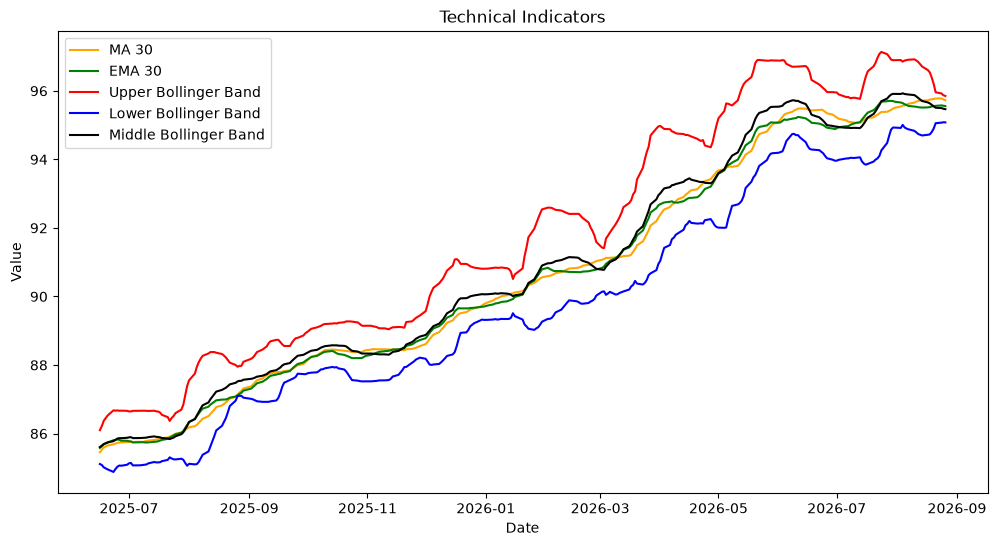

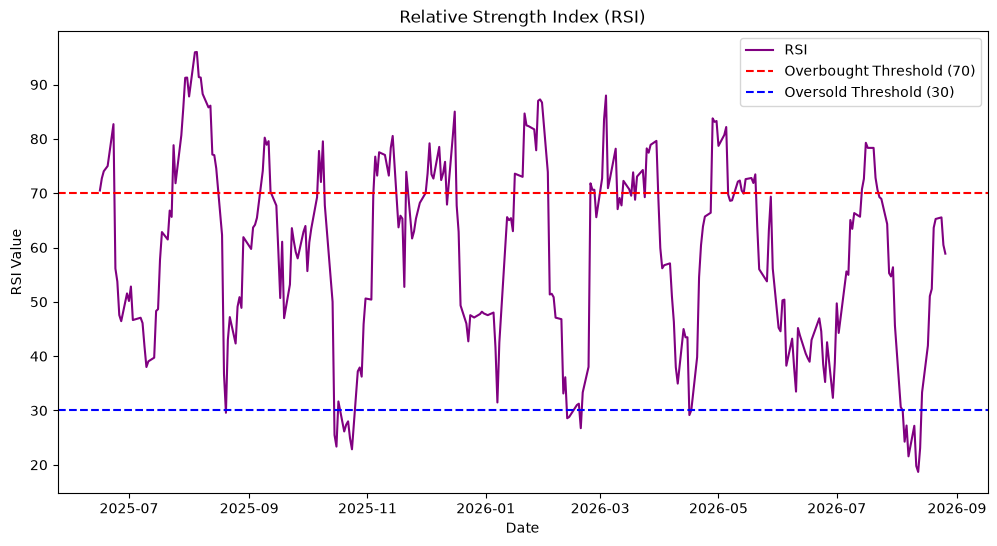

In [9]:
# Plot data with technical indicators - MA30, EMA30, RSI, bollinger bands
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(technical_data[-300:].index, technical_data[-300:]["MA_30"], label="MA 30", color="orange")
plt.plot(technical_data[-300:].index, technical_data[-300:]["EMA_30"], label="EMA 30", color="green")
plt.plot(technical_data[-300:].index, technical_data[-300:]["BB_Upper"], label="Upper Bollinger Band", color="red")
plt.plot(technical_data[-300:].index, technical_data[-300:]["BB_Lower"], label="Lower Bollinger Band", color="blue")
plt.plot(technical_data[-300:].index, technical_data[-300:]["BB_Middle"], label="Middle Bollinger Band", color="black")
plt.title("Technical Indicators")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.show()

## RSI
plt.figure(figsize=(12, 6))
plt.plot(technical_data[-300:].index, technical_data[-300:]["RSI"], label="RSI", color="purple")
plt.title("Relative Strength Index (RSI)")
plt.xlabel("Date")
plt.ylabel("RSI Value")
plt.axhline(70, color="red", linestyle="--", label="Overbought Threshold (70)")
plt.axhline(30, color="blue", linestyle="--", label="Oversold Threshold (30)")
plt.legend()
plt.show()

### Analysis of tecchnical data

<Axes: >

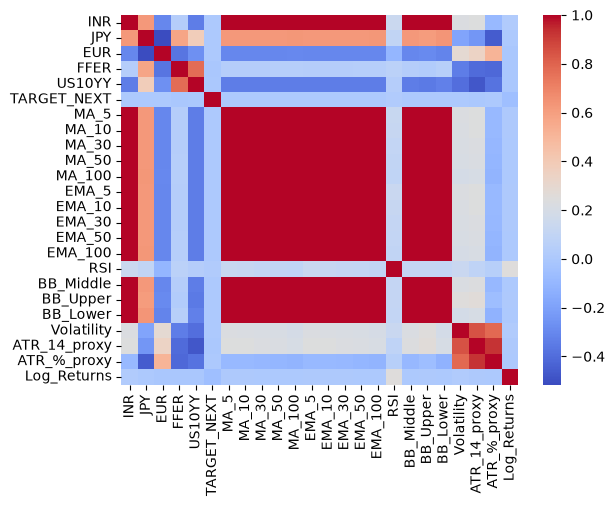

In [10]:
##  code to plot the technical indicators

sns.heatmap(technical_data.corr(), cmap="coolwarm")

In [11]:
NUM_INPUT_FEATURES = len(FEATURE_COLUMNS) + 1 + 12  # Original features + target + technical indicators
OUTPUT_FEATURES = 1  # Predicting the next price

train_df_ta, val_df_ta, test_df_ta = split_data(
    technical_data,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
)

In [12]:
ta_columns = [
    "MA_5",
    "MA_10",
    "MA_30",
    "MA_50",
    "MA_100",
    "EMA_5",
    "EMA_10",
    "EMA_30",
    "EMA_50",
    "EMA_100",
    "RSI",
    "BB_Middle",
    "BB_Upper",
    "BB_Lower",
    "Volatility",
    "ATR_14_proxy",
    "ATR_%_proxy",
    "Log_Returns",
]

all_features = FEATURE_COLUMNS + [TARGET_COLUMN] + ta_columns

In [13]:
TARGET_COLUMN = "INR"
technical_target_column = "TARGET_NEXT"

In [14]:
feature_scaler = fit_standard_scaler(train_df_ta, all_features)

train_targets = train_df_ta["TARGET_NEXT"]
val_targets = val_df_ta["TARGET_NEXT"]
test_targets = test_df_ta["TARGET_NEXT"]
target_scaler = fit_standard_scaler(train_targets)

X_train = normalize_to_tensor(train_df_ta, feature_scaler, all_features)
X_val = normalize_to_tensor(val_df_ta, feature_scaler, all_features)
X_test = normalize_to_tensor(test_df_ta, feature_scaler, all_features)
y_train = normalize_to_tensor(train_targets, target_scaler)
y_val = normalize_to_tensor(val_targets, target_scaler)
y_test = normalize_to_tensor(test_targets, target_scaler)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

In [15]:
model_linear_ta = nn.Linear(NUM_INPUT_FEATURES, OUTPUT_FEATURES)
model_linear_ta_optimizer = optim.Adam(
    model_linear_ta.parameters(),
    lr=0.001,
)
model_linear_ta_loss_function = nn.MSELoss()

In [16]:
EPOCHS = 100

model_linear_ta_losses = train_torch_model(
    model_linear_ta,
    model_linear_ta_optimizer,
    model_linear_ta_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 1.0768, Val Loss: 0.5277
Epoch 20/100, Train Loss: 1.0608, Val Loss: 0.5666
Epoch 30/100, Train Loss: 1.0480, Val Loss: 0.5278
Epoch 40/100, Train Loss: 1.0376, Val Loss: 0.5241
Epoch 50/100, Train Loss: 1.0292, Val Loss: 0.5185
Epoch 60/100, Train Loss: 1.0225, Val Loss: 0.5127
Epoch 70/100, Train Loss: 1.0172, Val Loss: 0.5091
Epoch 80/100, Train Loss: 1.0131, Val Loss: 0.5036
Epoch 90/100, Train Loss: 1.0098, Val Loss: 0.4971
Epoch 100/100, Train Loss: 1.0071, Val Loss: 0.4908


Test MAE: 0.2420, Test MSE: 0.0981


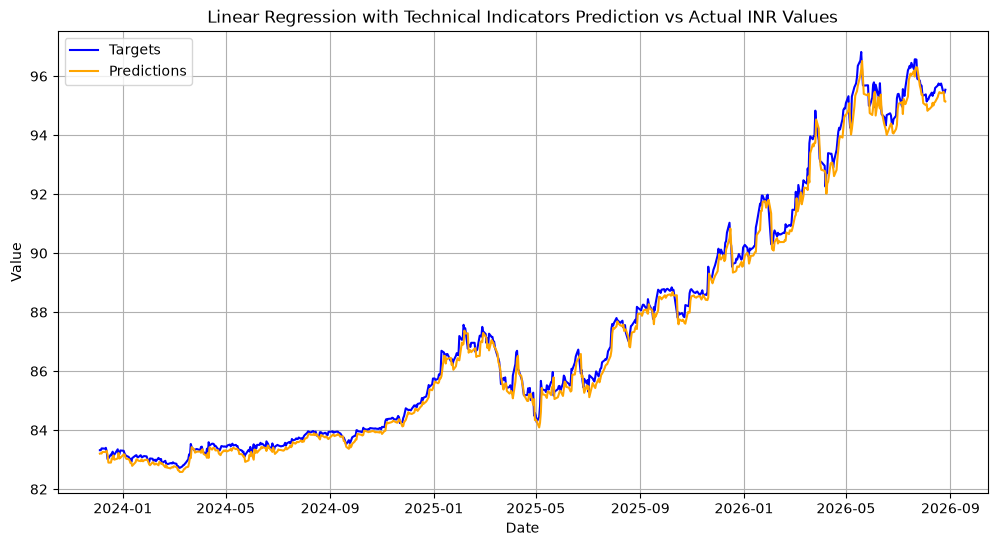

In [17]:
linear_ta_prediction_results = predict_and_store_log_return_model(
    model=model_linear_ta,
    model_name="Linear Regression with Technical Indicators",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_ta["INR"].values,
    test_current_prices=test_df_ta["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_linear_ta = linear_ta_prediction_results["train_predictions"]
predicted_prices_linear_ta = linear_ta_prediction_results["test_predictions"]
actual_train_prices_ta = linear_ta_prediction_results["train_actual_prices"]
actual_prices_ta = linear_ta_prediction_results["test_actual_prices"]
linear_ta_train_metrics = linear_ta_prediction_results["train_metrics"]
linear_ta_metrics = linear_ta_prediction_results["test_metrics"]

print(
    f"Test MAE: {linear_ta_metrics['mae']:.4f}, "
    f"Test MSE: {linear_ta_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_linear_ta,
    actual_prices_ta,
    x_values=test_df_ta.index,
    title="Linear Regression with Technical Indicators Prediction vs Actual INR Values",
)

In [18]:
model_dl_ta = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
model_dl_ta_optimizer = optim.Adam(
    model_dl_ta.parameters(),
    lr=0.001,
)
model_dl_ta_loss_function = nn.MSELoss()

In [19]:
train_losses_dl_ta = train_torch_model(
    model_dl_ta,
    model_dl_ta_optimizer,
    model_dl_ta_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 0.9943, Val Loss: 0.4163
Epoch 20/100, Train Loss: 0.9885, Val Loss: 0.4096
Epoch 30/100, Train Loss: 0.9841, Val Loss: 0.4110
Epoch 40/100, Train Loss: 0.9806, Val Loss: 0.4092
Epoch 50/100, Train Loss: 0.9768, Val Loss: 0.4088
Epoch 60/100, Train Loss: 0.9728, Val Loss: 0.4092
Epoch 70/100, Train Loss: 0.9684, Val Loss: 0.4103
Epoch 80/100, Train Loss: 0.9630, Val Loss: 0.4155
Epoch 90/100, Train Loss: 0.9573, Val Loss: 0.4237
Epoch 100/100, Train Loss: 0.9511, Val Loss: 0.4328


Test MAE: 0.1917, Test MSE: 0.0652


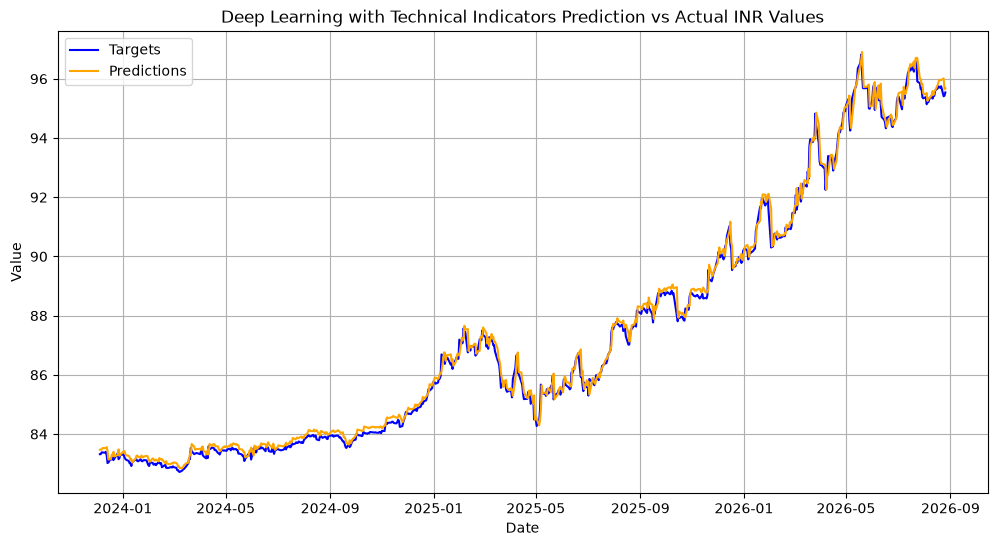

In [20]:
deep_ta_prediction_results = predict_and_store_log_return_model(
    model=model_dl_ta,
    model_name="Deep Learning with Technical Indicators",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_ta["INR"].values,
    test_current_prices=test_df_ta["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_ta = deep_ta_prediction_results["train_predictions"]
predicted_prices_ta = deep_ta_prediction_results["test_predictions"]
actual_train_prices_ta = deep_ta_prediction_results["train_actual_prices"]
actual_prices_ta = deep_ta_prediction_results["test_actual_prices"]
deep_ta_train_metrics = deep_ta_prediction_results["train_metrics"]
deep_ta_metrics = deep_ta_prediction_results["test_metrics"]

print(
    f"Test MAE: {deep_ta_metrics['mae']:.4f}, "
    f"Test MSE: {deep_ta_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_ta,
    actual_prices_ta,
    x_values=test_df_ta.index,
    title="Deep Learning with Technical Indicators Prediction vs Actual INR Values",
)

## ADD NEW TEMPORAL FEATURES

In [21]:
TEMPORAL_FEATURES_NUMBER = 5  # Number of temporal features to include

In [22]:
import pandas as pd

def create_temporal_features(df, target_columns=None, num_features=5):
    """Add lagged temporal features"""
    df = df.copy()

    if target_columns is None:
        target_columns = [
            column for column in df.columns
            if column != "TARGET_NEXT"
        ]

    lagged_features = [
        df[target_columns]
        .shift(lag)
        .add_suffix(f"_lag_{lag}")
        for lag in range(1, num_features + 1)
    ]

    return pd.concat([df, *lagged_features], axis=1)


In [23]:
train_df_temp = create_temporal_features(
    train_df_ta.copy(),
    None,
    TEMPORAL_FEATURES_NUMBER,
).dropna()
val_df_temp = create_temporal_features(
    val_df_ta.copy(),
    None,
    TEMPORAL_FEATURES_NUMBER,
).dropna()
test_df_temp = create_temporal_features(
    test_df_ta.copy(),
    None,
    TEMPORAL_FEATURES_NUMBER,
).dropna()

In [24]:
train_df_temp.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 5439 entries, 1999-06-02 to 2021-03-16
Columns: 139 entries, INR to Log_Returns_lag_5
dtypes: float64(139)
memory usage: 5.8 MB


In [25]:
temporal_features = all_features + [
    f"{feature}_lag_{lag}"
    for feature in all_features
    for lag in range(1, TEMPORAL_FEATURES_NUMBER + 1)
]

feature_scaler_temp = fit_standard_scaler(train_df_temp, temporal_features)

train_targets = train_df_temp["TARGET_NEXT"]
val_targets = val_df_temp["TARGET_NEXT"]
test_targets = test_df_temp["TARGET_NEXT"]
target_scaler = fit_standard_scaler(train_targets)

X_train = normalize_to_tensor(train_df_temp, feature_scaler_temp, temporal_features)
X_val = normalize_to_tensor(val_df_temp, feature_scaler_temp, temporal_features)
X_test = normalize_to_tensor(test_df_temp, feature_scaler_temp, temporal_features)
y_train = normalize_to_tensor(train_targets, target_scaler)
y_val = normalize_to_tensor(val_targets, target_scaler)
y_test = normalize_to_tensor(test_targets, target_scaler)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

In [26]:
model_dl_temp = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(32, 1)
)
model_dl_temp_optimizer = optim.Adam(
    model_dl_temp.parameters(),
    lr=0.001,
)
model_dl_temp_loss_function = nn.MSELoss()

In [27]:
train_losses_dl_temp = train_torch_model(
    model_dl_temp,
    model_dl_temp_optimizer,
    model_dl_temp_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 0.9911, Val Loss: 0.4132
Epoch 20/100, Train Loss: 0.9867, Val Loss: 0.4160
Epoch 30/100, Train Loss: 0.9811, Val Loss: 0.4160
Epoch 40/100, Train Loss: 0.9719, Val Loss: 0.4178
Epoch 50/100, Train Loss: 0.9650, Val Loss: 0.4197
Epoch 60/100, Train Loss: 0.9571, Val Loss: 0.4228
Epoch 70/100, Train Loss: 0.9487, Val Loss: 0.4203
Epoch 80/100, Train Loss: 0.9499, Val Loss: 0.4216
Epoch 90/100, Train Loss: 0.9325, Val Loss: 0.4248
Epoch 100/100, Train Loss: 0.9347, Val Loss: 0.4237


Test MAE: 0.1558, Test MSE: 0.0574


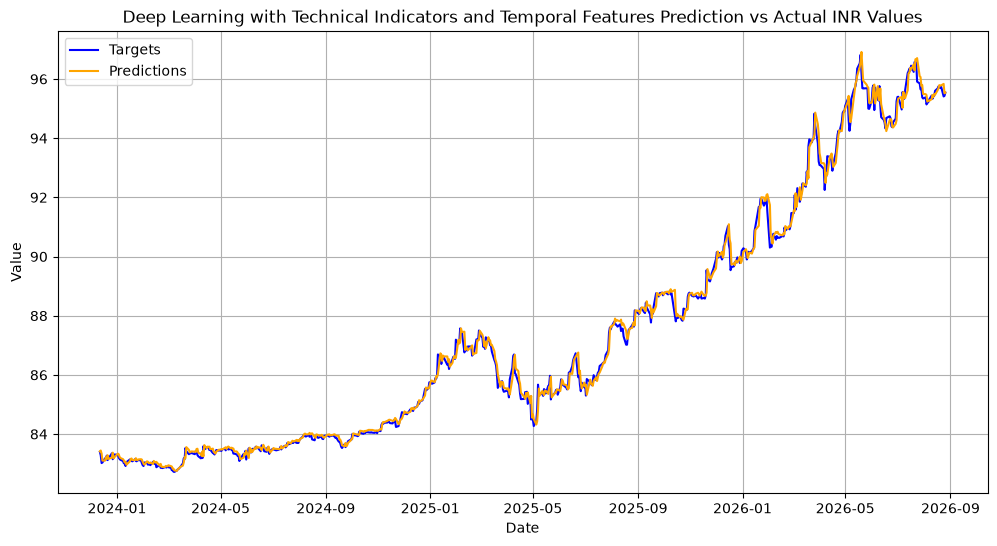

In [28]:
deep_temp_prediction_results = predict_and_store_log_return_model(
    model=model_dl_temp,
    model_name="Deep Learning with Technical Indicators and Temporal Features",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_temp["INR"].values,
    test_current_prices=test_df_temp["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_temp = deep_temp_prediction_results["train_predictions"]
predicted_prices_temp = deep_temp_prediction_results["test_predictions"]
actual_train_prices_temp = deep_temp_prediction_results["train_actual_prices"]
actual_prices_temp = deep_temp_prediction_results["test_actual_prices"]
deep_temp_train_metrics = deep_temp_prediction_results["train_metrics"]
deep_temp_metrics = deep_temp_prediction_results["test_metrics"]

print(
    f"Test MAE: {deep_temp_metrics['mae']:.4f}, "
    f"Test MSE: {deep_temp_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_temp,
    actual_prices_temp,
    x_values=test_df_temp.index,
    title="Deep Learning with Technical Indicators and Temporal Features Prediction vs Actual INR Values",
)

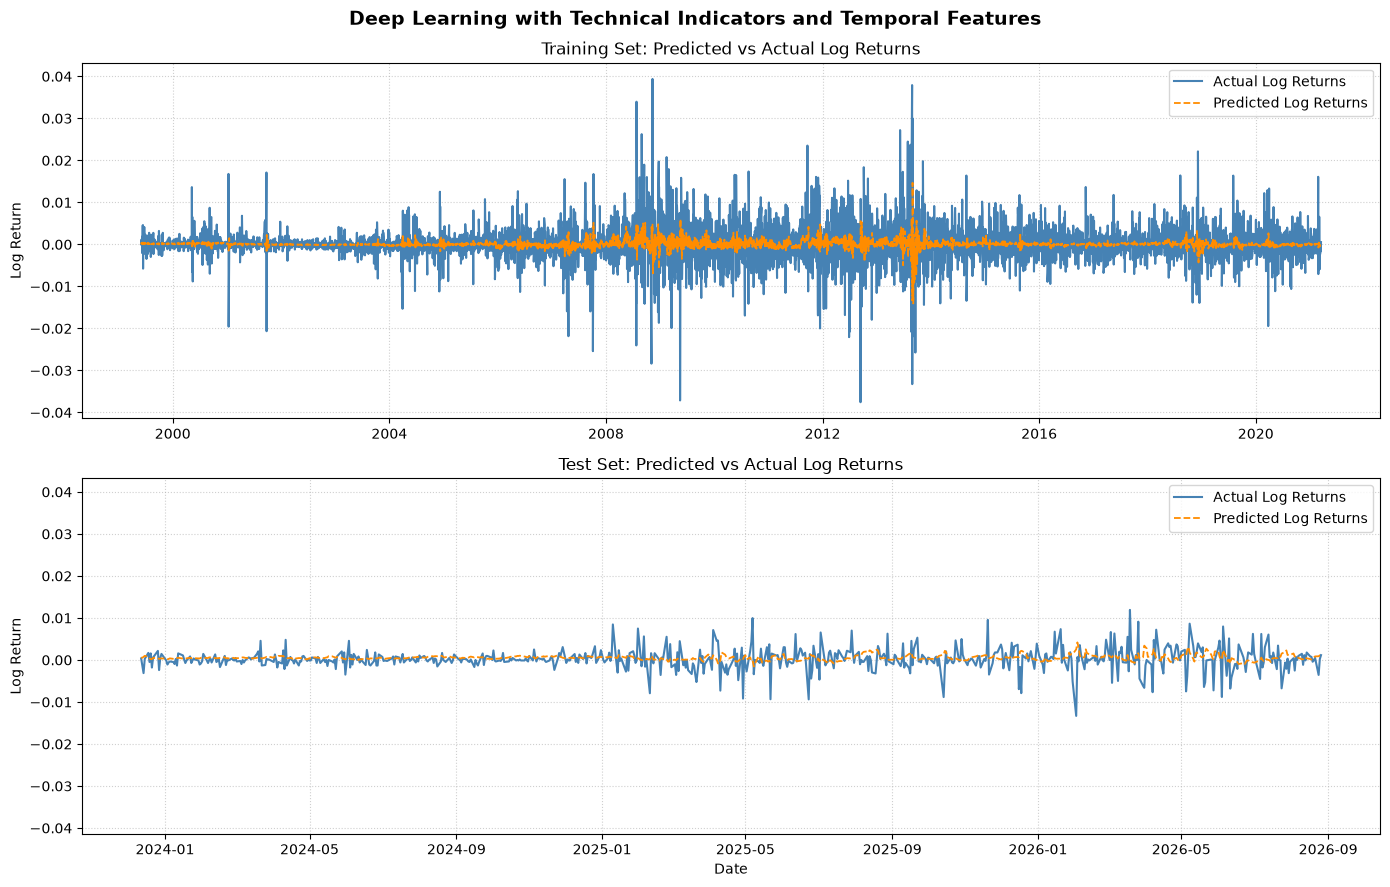

In [29]:
# PLOT PREDICTED LOG RETURNS vs ACTUAL LOG RETURNS
import matplotlib.pyplot as plt

predicted_train_log_returns = np.log(
    predicted_train_prices_temp / train_df_temp["INR"].to_numpy()
)
actual_train_log_returns = np.log(
    actual_train_prices_temp / train_df_temp["INR"].to_numpy()
)
predicted_test_log_returns = np.log(
    predicted_prices_temp / test_df_temp["INR"].to_numpy()
)
actual_test_log_returns = np.log(
    actual_prices_temp / test_df_temp["INR"].to_numpy()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharey=True)

axes[0].plot(
    train_df_temp.index,
    actual_train_log_returns,
    label="Actual Log Returns",
    color="steelblue",
    linewidth=1.5,
)
axes[0].plot(
    train_df_temp.index,
    predicted_train_log_returns,
    label="Predicted Log Returns",
    color="darkorange",
    linestyle="--",
    linewidth=1.3,
)
axes[0].set_title("Training Set: Predicted vs Actual Log Returns")
axes[0].set_ylabel("Log Return")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].plot(
    test_df_temp.index,
    actual_test_log_returns,
    label="Actual Log Returns",
    color="steelblue",
    linewidth=1.5,
)
axes[1].plot(
    test_df_temp.index,
    predicted_test_log_returns,
    label="Predicted Log Returns",
    color="darkorange",
    linestyle="--",
    linewidth=1.3,
)
axes[1].set_title("Test Set: Predicted vs Actual Log Returns")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Log Return")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

fig.suptitle(
    "Deep Learning with Technical Indicators and Temporal Features",
    fontsize=14,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

## LSTM Model with Technical Indicators (Target: Log Returns + Directional Loss)

Financial log returns have a very low signal-to-noise ratio. A standard Mean Squared Error (MSE) loss causes the model to simply predict the mean (near zero) to minimize error, resulting in a flat-line prediction.

To fix this 'mean-seeking' behavior, we apply three fixes:
1. **Big-Move Aware Directional Loss**: Adds a heavy penalty when the predicted sign (Up/Down) doesn't match the actual sign, forcing the model to take a stance.
2. **Reduce Model Complexity**: Use 1 LSTM layer with 32 units to prevent the optimizer from getting stuck over-regularizing.
3. **Shorten Lookback Window**: Use 10 days instead of 30 to focus on recent price action rather than distant noise.

In [30]:
# ────────────────────────────────────────────────────────────────────────────
# Prepare technical-indicator data for the LSTM model
# ────────────────────────────────────────────────────────────────────────────
from utils import (
    create_time_series_dataloaders,
    train_torch_model_dataloader,
    predict_and_store_window_model,
    evaluate_torch_model_dataloader,
    plot_predictions_vs_targets,
)
import torch
import torch.nn as nn
import torch.optim as optim

lstm_df = calculate_technical_indicators(full_df, target_column=TARGET_COLUMN)
lstm_df["TARGET_LOG_RETURN_NEXT"] = lstm_df["Log_Returns"].shift(-1)
lstm_df = lstm_df.dropna()

LSTM_FEATURE_COLS = [
    TARGET_COLUMN,
    *FEATURE_COLUMNS,
    "MA_5", "MA_10", "MA_30", "MA_50", "MA_100",
    "EMA_5", "EMA_10", "EMA_30", "EMA_50", "EMA_100",
    "RSI",
    "BB_Middle", "BB_Upper", "BB_Lower",
    "Volatility",
    "ATR_14_proxy", "ATR_%_proxy",
    "Log_Returns",
]

LSTM_WINDOW_SIZE = 10     # Shorter window to focus on recent price action
LSTM_HIDDEN_SIZE = 32     # Smaller network to avoid mean-collapse
LSTM_NUM_LAYERS = 1
LSTM_DROPOUT = 0.0
LSTM_LR = 1e-3
LSTM_EPOCHS = 80
LSTM_BATCH_SIZE = 32
LSTM_PATIENCE = 10

print(f"LSTM dataframe shape: {lstm_df.shape}")


LSTM dataframe shape: (6805, 25)


In [31]:
# ────────────────────────────────────────────────────────────────────────────
# Create windowed dataloaders predicting Log Returns
# ────────────────────────────────────────────────────────────────────────────
lstm_loaders = create_time_series_dataloaders(
    data=lstm_df,
    target_column="TARGET_LOG_RETURN_NEXT",
    feature_columns=LSTM_FEATURE_COLS,
    window_size=LSTM_WINDOW_SIZE,
    offset=0,
    target_size=1,
    stride=1,
    batch_size=LSTM_BATCH_SIZE,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
    scale_features=True,
    scale_targets=True,
    shuffle_train=True,
    device=DEVICE,
)
print(f"Train samples: {len(lstm_loaders['train_dataset'])}")


Train samples: 5434


In [32]:
# ────────────────────────────────────────────────────────────────────────────
# LSTM Model Definition
# ────────────────────────────────────────────────────────────────────────────
class LSTMForecaster(nn.Module):
    def __init__(self, input_size, hidden_size=32, num_layers=1, dropout=0.0, output_size=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        lstm_out, (h_n, _) = self.lstm(x)
        last_hidden = h_n[-1]
        out = self.dropout(last_hidden)
        out = self.fc(out)
        return out.squeeze(-1)

lstm_model = LSTMForecaster(
    input_size=len(LSTM_FEATURE_COLS),
    hidden_size=LSTM_HIDDEN_SIZE,
    num_layers=LSTM_NUM_LAYERS,
    dropout=LSTM_DROPOUT,
).to(DEVICE)


In [33]:
# ────────────────────────────────────────────────────────────────────────────
# Custom Directional Loss & Training
# ────────────────────────────────────────────────────────────────────────────
class BigMoveAwareLoss(nn.Module):
    """
    Penalizes both directional mismatches AND missing large market moves.
    Explicitly targets moves >= 1.5 sigma for heavy penalization.
    """
    def __init__(self, dir_penalty=0.5, mag_penalty=2.0, sigma_threshold=1.5):
        super().__init__()
        self.mse = nn.MSELoss(reduction='none')
        self.dir_penalty = dir_penalty
        self.mag_penalty = mag_penalty
        self.sigma_threshold = sigma_threshold
        
    def forward(self, y_pred, y_true):
        sq_error = self.mse(y_pred, y_true)
        
        weight = 1.0 + self.mag_penalty * torch.abs(y_true)
        big_move_mask = (torch.abs(y_true) >= self.sigma_threshold).float()
        weight = weight + (big_move_mask * self.mag_penalty * 2.0)
        
        weighted_mse = sq_error * weight
        
        sign_mismatch = torch.relu(-torch.sign(y_pred) * torch.sign(y_true))
        dir_weight = torch.abs(y_true) + (big_move_mask * 2.0)
        dir_loss = sign_mismatch * dir_weight * self.dir_penalty
        
        return torch.mean(weighted_mse + dir_loss)

lstm_optimizer = optim.Adam(lstm_model.parameters(), lr=LSTM_LR, weight_decay=1e-5)
lstm_loss_fn = BigMoveAwareLoss(dir_penalty=0.5, mag_penalty=2.0, sigma_threshold=1.5)
lstm_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    lstm_optimizer, mode="min", factor=0.5, patience=4, verbose=True
)

lstm_history = train_torch_model_dataloader(
    model=lstm_model,
    optimizer=lstm_optimizer,
    loss_function=lstm_loss_fn,
    train_loader=lstm_loaders["train_loader"],
    val_loader=lstm_loaders["val_loader"],
    epochs=LSTM_EPOCHS,
    device=DEVICE,
    log_every=10,
    scheduler=lstm_scheduler,
    early_stopping_patience=LSTM_PATIENCE,
)


c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 10/80 - Train Loss: 9.3642, Val Loss: 2.2656
Early stopping triggered at epoch 15. Restoring best weights (Val Loss: 2.0991).


In [34]:
# ────────────────────────────────────────────────────────────────────────────
# Evaluate LSTM and store predictions (Log Returns scale)
# ────────────────────────────────────────────────────────────────────────────
lstm_eval_results = predict_and_store_window_model(
    model=lstm_model,
    model_name="LSTM + Tech Indicators (Directional)",
    loaders_dict=lstm_loaders,
    model_results=model_results,
    device=DEVICE,
    output_path=str(RESULTS_PATH),
    metadata={"window_size": LSTM_WINDOW_SIZE, "target": "Log_Returns"},
    price_data=lstm_df,
    price_column=TARGET_COLUMN,
)

for split_name in ["train", "validation", "test"]:
    result = lstm_eval_results.get(split_name)
    if result is not None:
        m = result["metrics"]
        print(f"{split_name.capitalize():>12s} — MAE: {m['mae']:.5f}  RMSE: {m['rmse']:.5f}  Dir. Acc: {m['directional_accuracy']:.2f}%")


       Train — MAE: 0.00280  RMSE: 0.00434  Dir. Acc: 74.23%
  Validation — MAE: 0.00208  RMSE: 0.00283  Dir. Acc: 72.46%
        Test — MAE: 0.00181  RMSE: 0.00263  Dir. Acc: 67.79%


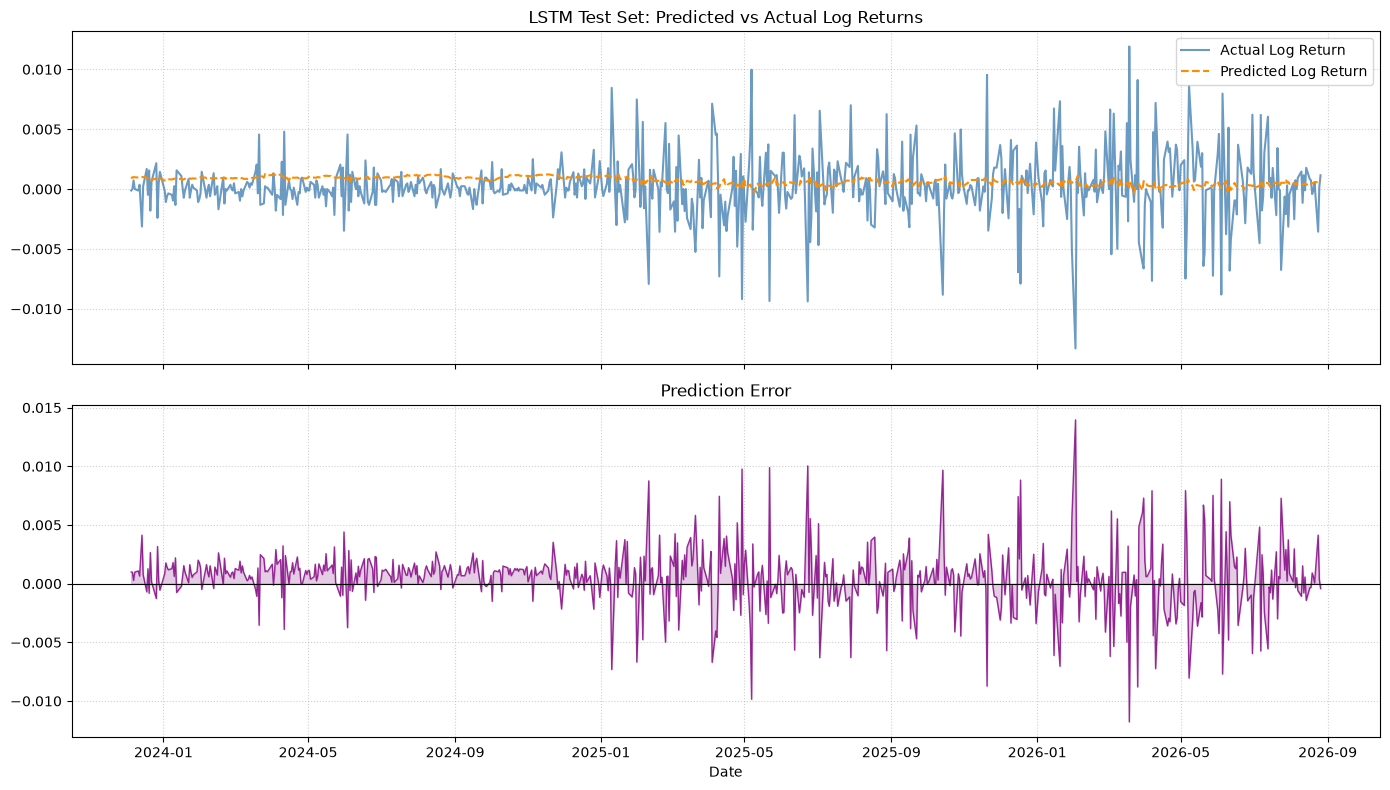

In [35]:
# ────────────────────────────────────────────────────────────────────────────
# Plot LSTM predictions vs actuals for Log Returns (Test set)
# ────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
test_result = lstm_eval_results["test"]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(test_result["dates"], test_result["targets"], label="Actual Log Return", color="steelblue", alpha=0.8)
axes[0].plot(test_result["dates"], test_result["predictions"], label="Predicted Log Return", color="darkorange", linestyle="--", linewidth=1.5)
axes[0].set_title("LSTM Test Set: Predicted vs Actual Log Returns")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

errors = test_result["predictions"] - test_result["targets"]
# Use plot and fill_between instead of bar to avoid empty plots on datetime axes
axes[1].plot(test_result["dates"], errors, color="purple", linewidth=1.0, alpha=0.8)
axes[1].fill_between(test_result["dates"], 0, errors, color="purple", alpha=0.2)
axes[1].axhline(y=0, color="black", linewidth=0.8)
axes[1].set_title("Prediction Error")
axes[1].set_xlabel("Date")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## EUR/USD LSTM Model (Target: Log Returns + Directional Loss)

Applying the exact same directional LSTM architecture to the EUR/USD exchange rate.
We calculate technical indicators centered on EUR as the target.

In [36]:
# ────────────────────────────────────────────────────────────────────────────
# Prepare technical-indicator data for EUR/USD
# ────────────────────────────────────────────────────────────────────────────

eur_df = calculate_technical_indicators(full_df, target_column="EUR")
eur_df["TARGET_LOG_RETURN_NEXT"] = eur_df["Log_Returns"].shift(-1)
eur_df = eur_df.dropna()

EUR_FEATURE_COLUMNS = ["INR", "JPY", "FFER", "US10YY"]
EUR_LSTM_FEATURE_COLS = [
    "EUR",
    *EUR_FEATURE_COLUMNS,
    "MA_5", "MA_10", "MA_30", "MA_50", "MA_100",
    "EMA_5", "EMA_10", "EMA_30", "EMA_50", "EMA_100",
    "RSI",
    "BB_Middle", "BB_Upper", "BB_Lower",
    "Volatility",
    "ATR_14_proxy", "ATR_%_proxy",
    "Log_Returns",
]

print(f"EUR LSTM dataframe shape: {eur_df.shape}")


EUR LSTM dataframe shape: (6805, 25)


In [57]:
eur_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 6805 entries, 1999-05-25 to 2026-08-26
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   INR                     6805 non-null   float64
 1   JPY                     6805 non-null   float64
 2   EUR                     6805 non-null   float64
 3   FFER                    6805 non-null   float64
 4   US10YY                  6805 non-null   float64
 5   TARGET_NEXT             6805 non-null   float64
 6   MA_5                    6805 non-null   float64
 7   MA_10                   6805 non-null   float64
 8   MA_30                   6805 non-null   float64
 9   MA_50                   6805 non-null   float64
 10  MA_100                  6805 non-null   float64
 11  EMA_5                   6805 non-null   float64
 12  EMA_10                  6805 non-null   float64
 13  EMA_30                  6805 non-null   float64
 14  EMA_50                  6805 non-

In [37]:
# ────────────────────────────────────────────────────────────────────────────
# Create windowed dataloaders predicting EUR Log Returns
# ────────────────────────────────────────────────────────────────────────────
eur_lstm_loaders = create_time_series_dataloaders(
    data=eur_df,
    target_column="Log_Returns",
    feature_columns=EUR_LSTM_FEATURE_COLS,
    window_size=LSTM_WINDOW_SIZE,
    offset=0,
    target_size=1,
    stride=1,
    batch_size=LSTM_BATCH_SIZE,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
    scale_features=True,
    scale_targets=True,
    shuffle_train=True,
    device=DEVICE,
)
print(f"Train samples: {len(eur_lstm_loaders['train_dataset'])}")


Train samples: 5434


In [59]:
eur_df.info()

train_dataset = eur_lstm_loaders["train_dataset"]
print(f"Dataset type: {type(train_dataset).__name__}")
print(f"Number of windows: {len(train_dataset)}")

sample_x, sample_y = train_dataset[0]
print(f"Sample input shape: {sample_x.shape}")
print(f"Sample target shape: {sample_y.shape}")

<class 'pandas.DataFrame'>
DatetimeIndex: 6805 entries, 1999-05-25 to 2026-08-26
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   INR                     6805 non-null   float64
 1   JPY                     6805 non-null   float64
 2   EUR                     6805 non-null   float64
 3   FFER                    6805 non-null   float64
 4   US10YY                  6805 non-null   float64
 5   TARGET_NEXT             6805 non-null   float64
 6   MA_5                    6805 non-null   float64
 7   MA_10                   6805 non-null   float64
 8   MA_30                   6805 non-null   float64
 9   MA_50                   6805 non-null   float64
 10  MA_100                  6805 non-null   float64
 11  EMA_5                   6805 non-null   float64
 12  EMA_10                  6805 non-null   float64
 13  EMA_30                  6805 non-null   float64
 14  EMA_50                  6805 non-

In [38]:
# ────────────────────────────────────────────────────────────────────────────
# Initialize & Train EUR LSTM Model
# ────────────────────────────────────────────────────────────────────────────
eur_lstm_model = LSTMForecaster(
    input_size=len(EUR_LSTM_FEATURE_COLS),
    hidden_size=LSTM_HIDDEN_SIZE,
    num_layers=LSTM_NUM_LAYERS,
    dropout=LSTM_DROPOUT,
).to(DEVICE)

eur_lstm_optimizer = optim.Adam(eur_lstm_model.parameters(), lr=LSTM_LR, weight_decay=1e-5)
eur_lstm_loss_fn = BigMoveAwareLoss(dir_penalty=0.5, mag_penalty=2.0, sigma_threshold=1.5)
eur_lstm_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    eur_lstm_optimizer, mode="min", factor=0.5, patience=4, verbose=True
)

eur_lstm_history = train_torch_model_dataloader(
    model=eur_lstm_model,
    optimizer=eur_lstm_optimizer,
    loss_function=eur_lstm_loss_fn,
    train_loader=eur_lstm_loaders["train_loader"],
    val_loader=eur_lstm_loaders["val_loader"],
    epochs=LSTM_EPOCHS,
    device=DEVICE,
    log_every=10,
    scheduler=eur_lstm_scheduler,
    early_stopping_patience=LSTM_PATIENCE,
)


c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 10/80 - Train Loss: 7.3755, Val Loss: 4.7198
Early stopping triggered at epoch 13. Restoring best weights (Val Loss: 4.2814).


In [39]:
# ────────────────────────────────────────────────────────────────────────────
# Evaluate EUR LSTM and store predictions
# ────────────────────────────────────────────────────────────────────────────
eur_lstm_eval_results = predict_and_store_window_model(
    model=eur_lstm_model,
    model_name="EUR LSTM + Tech Indicators (Directional)",
    loaders_dict=eur_lstm_loaders,
    model_results=model_results,
    device=DEVICE,
    output_path=str(RESULTS_PATH),
    metadata={"window_size": LSTM_WINDOW_SIZE, "target": "EUR_Log_Returns"},
    price_data=eur_df,
    price_column="EUR",
)

for split_name in ["train", "validation", "test"]:
    result = eur_lstm_eval_results.get(split_name)
    if result is not None:
        m = result["metrics"]
        print(f"{split_name.capitalize():>12s} — MAE: {m['mae']:.5f}  RMSE: {m['rmse']:.5f}  Dir. Acc: {m['directional_accuracy']:.2f}%")


       Train — MAE: 0.00445  RMSE: 0.00602  Dir. Acc: 74.95%
  Validation — MAE: 0.00383  RMSE: 0.00508  Dir. Acc: 74.67%
        Test — MAE: 0.00310  RMSE: 0.00423  Dir. Acc: 75.59%


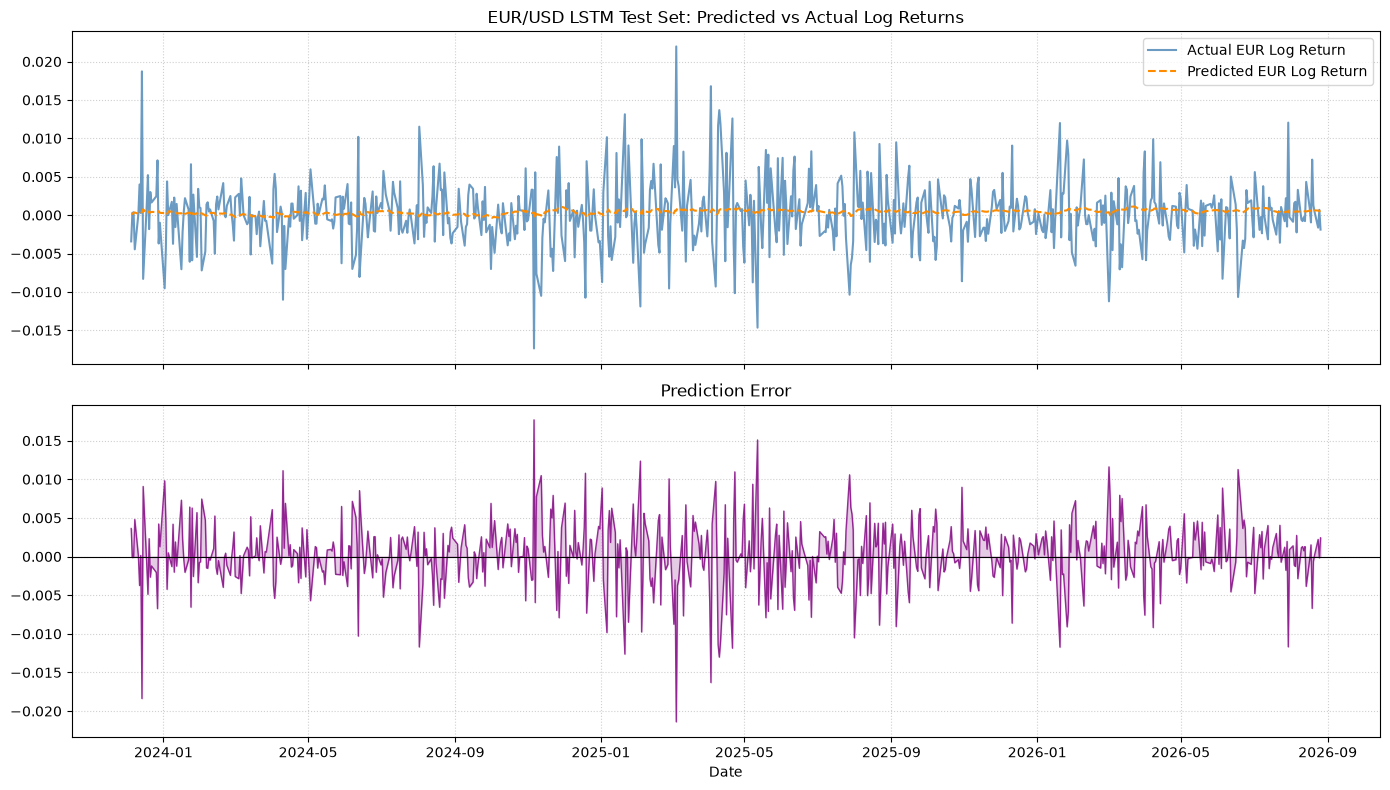

In [40]:
# ────────────────────────────────────────────────────────────────────────────
# Plot EUR LSTM predictions vs actuals (Test set)
# ────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
eur_test_result = eur_lstm_eval_results["test"]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(eur_test_result["dates"], eur_test_result["targets"], label="Actual EUR Log Return", color="steelblue", alpha=0.8)
axes[0].plot(eur_test_result["dates"], eur_test_result["predictions"], label="Predicted EUR Log Return", color="darkorange", linestyle="--", linewidth=1.5)
axes[0].set_title("EUR/USD LSTM Test Set: Predicted vs Actual Log Returns")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

errors = eur_test_result["predictions"] - eur_test_result["targets"]
axes[1].plot(eur_test_result["dates"], errors, color="purple", linewidth=1.0, alpha=0.8)
axes[1].fill_between(eur_test_result["dates"], 0, errors, color="purple", alpha=0.2)
axes[1].axhline(y=0, color="black", linewidth=0.8)
axes[1].set_title("Prediction Error")
axes[1].set_xlabel("Date")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


### CALCULATE PROFITS

In [41]:
from utils import AdvancedProfitCalculator

In [42]:
eur_lstm_eval_results["validation"].keys()

dict_keys(['predictions', 'targets', 'metrics', 'dates'])

In [43]:
print(eur_lstm_eval_results["validation"]["predictions"].size)
print(eur_lstm_eval_results["validation"]["targets"].size)
print(eur_lstm_eval_results["validation"]["dates"].size)

680
680
680


           INSTITUTIONAL QUANT TRADING PERFORMANCE REPORT
CAPITAL & RETURNS:
  Initial Capital        : $10,000.00
  Final Portfolio Value  : $19,035.45
  Strategy Net Return    : +90.35%
  Benchmark (Buy & Hold) : -9.80%
  Strategy Alpha         : +100.15%
  Annualized CAGR        : +26.94%
--------------------------------------------------------------------------------
TRADE EXECUTION & WIN/LOSS METRICS:
  Total Trades Executed  : 582 (Long: 329, Short: 253, Neutral: 98)
  Winning Trades         : 284 (48.80%)
  Losing Trades          : 298 (51.20%)
  Average Win ($)        : $151.08
  Average Loss ($)       : $113.66
  Realized Risk/Reward   : 1.33
  Gross Profit           : $42,906.32
  Gross Loss             : $33,870.87
  Profit Factor          : 1.27
  Trade Expectancy       : $15.52 per trade
--------------------------------------------------------------------------------
RISK-ADJUSTED METRICS:
  Max Drawdown           : -13.81%
  Annualized Sharpe      : 1.54
  Annualized Sort

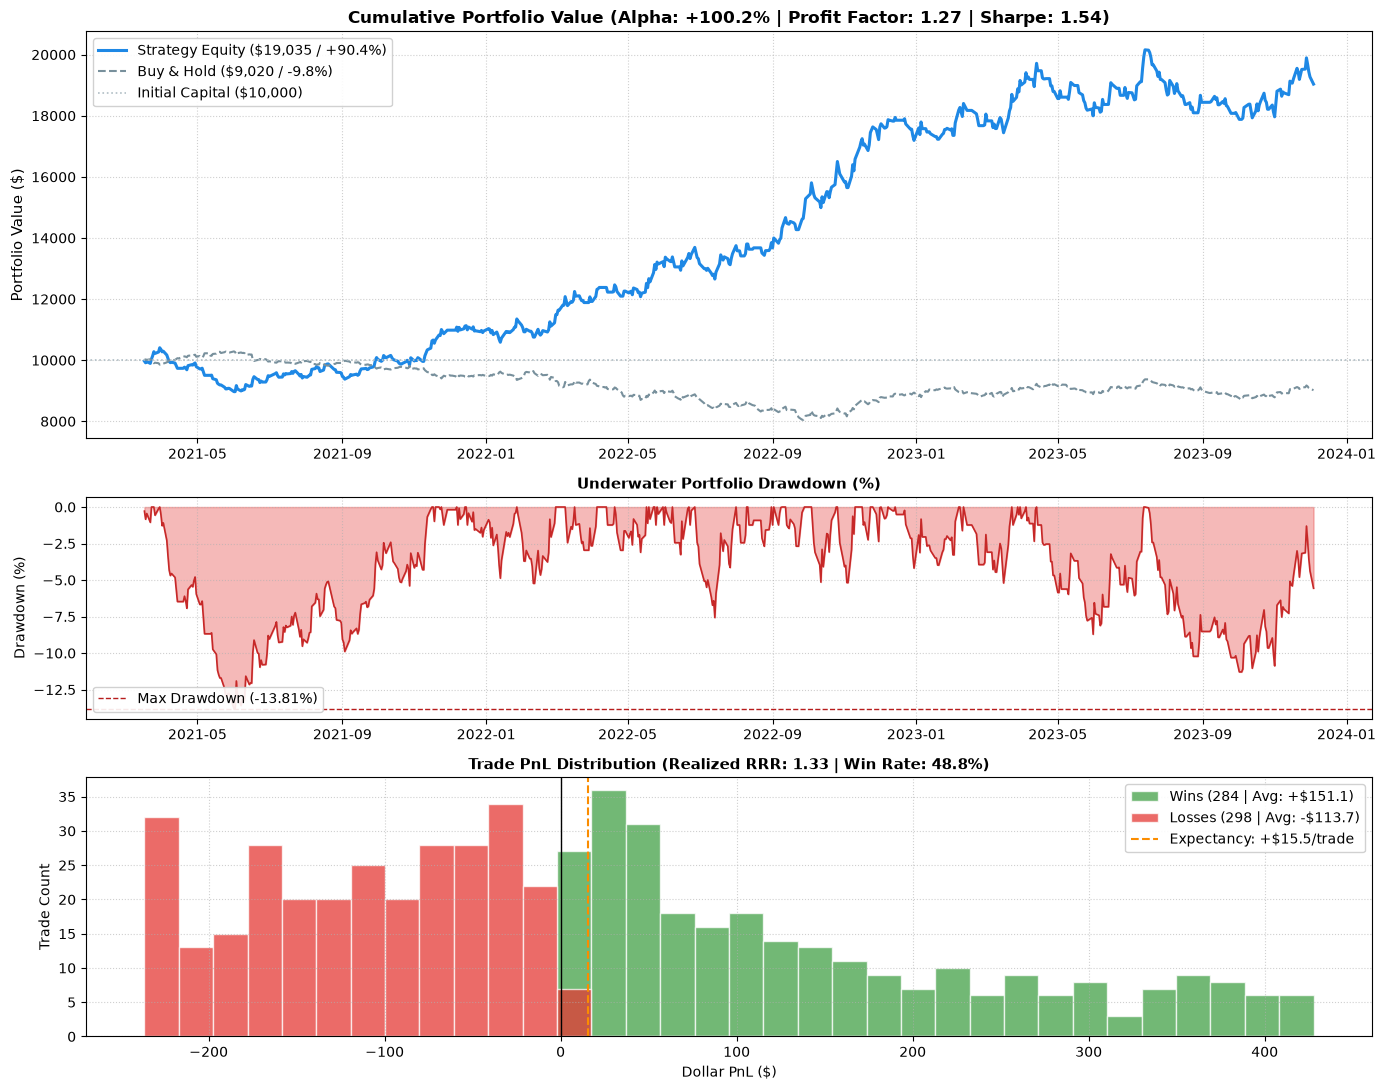

In [44]:
# 1. Instantiate the quantitative backtester
# You can test on "validation" or "test"
split = "validation"

calculator = AdvancedProfitCalculator(
    predictions=eur_lstm_eval_results[split]["predictions"],
    actual_returns=eur_lstm_eval_results[split]["targets"],
    initial_capital=10000.0,
    stop_loss=0.004,         # 0.40% Stop Loss
    risk_reward_ratio=2.0,   # 1:2 RRR -> Auto-sets Take Profit to 0.80%
    threshold=0.0001,        # 1-pip deadzone filter (avoids noise below 0.01%)
    fee_per_trade=0.0001,    # 1-pip round-trip transaction friction
    risk_per_trade=0.02,     # Risk exactly 2% of portfolio equity per trade
    max_leverage=3.0,        # Conservative 3x forex leverage cap
    dates=eur_lstm_eval_results[split]["dates"],
)

# 2. Print institutional performance summary
calculator.summary()

# 3. Render 3-panel quant trading dashboard:
#    - Panel 1: Portfolio Equity Curve vs Buy & Hold Benchmark
#    - Panel 2: Underwater Drawdown Curve (%)
#    - Panel 3: Trade PnL Distribution (Histogram of Wins & Losses)
calculator.plot()

### GENETIC ALGORITHM FOR STRATEGY OPTIMISATION

         GENETIC ALGORITHM HYPERPARAMETER OPTIMIZATION STARTING
Population Size : 40 | Generations: 25 | Objective: CALMAR
Optimizing Genes: stop_loss, risk_reward_ratio, threshold, risk_per_trade, max_leverage
--------------------------------------------------------------------------------
Gen  0/25 | Best Fitness:    6.12 (Avg:   0.66) | SL: 0.0024 | RRR: 2.66 | Thresh: 0.00025 | Risk%: 2.28%
Gen  5/25 | Best Fitness:   17.38 (Avg:   9.07) | SL: 0.0020 | RRR: 3.46 | Thresh: 0.00000 | Risk%: 1.92%
Gen 10/25 | Best Fitness:   20.33 (Avg:  16.81) | SL: 0.0020 | RRR: 3.50 | Thresh: 0.00000 | Risk%: 2.48%
Gen 15/25 | Best Fitness:   20.33 (Avg:  18.55) | SL: 0.0020 | RRR: 3.50 | Thresh: 0.00000 | Risk%: 1.65%
Gen 20/25 | Best Fitness:   20.43 (Avg:  17.39) | SL: 0.0020 | RRR: 3.50 | Thresh: 0.00000 | Risk%: 2.82%
Gen 24/25 | Best Fitness:   20.43 (Avg:  18.75) | SL: 0.0020 | RRR: 3.50 | Thresh: 0.00000 | Risk%: 2.50%
------------------------------------------------------------------------

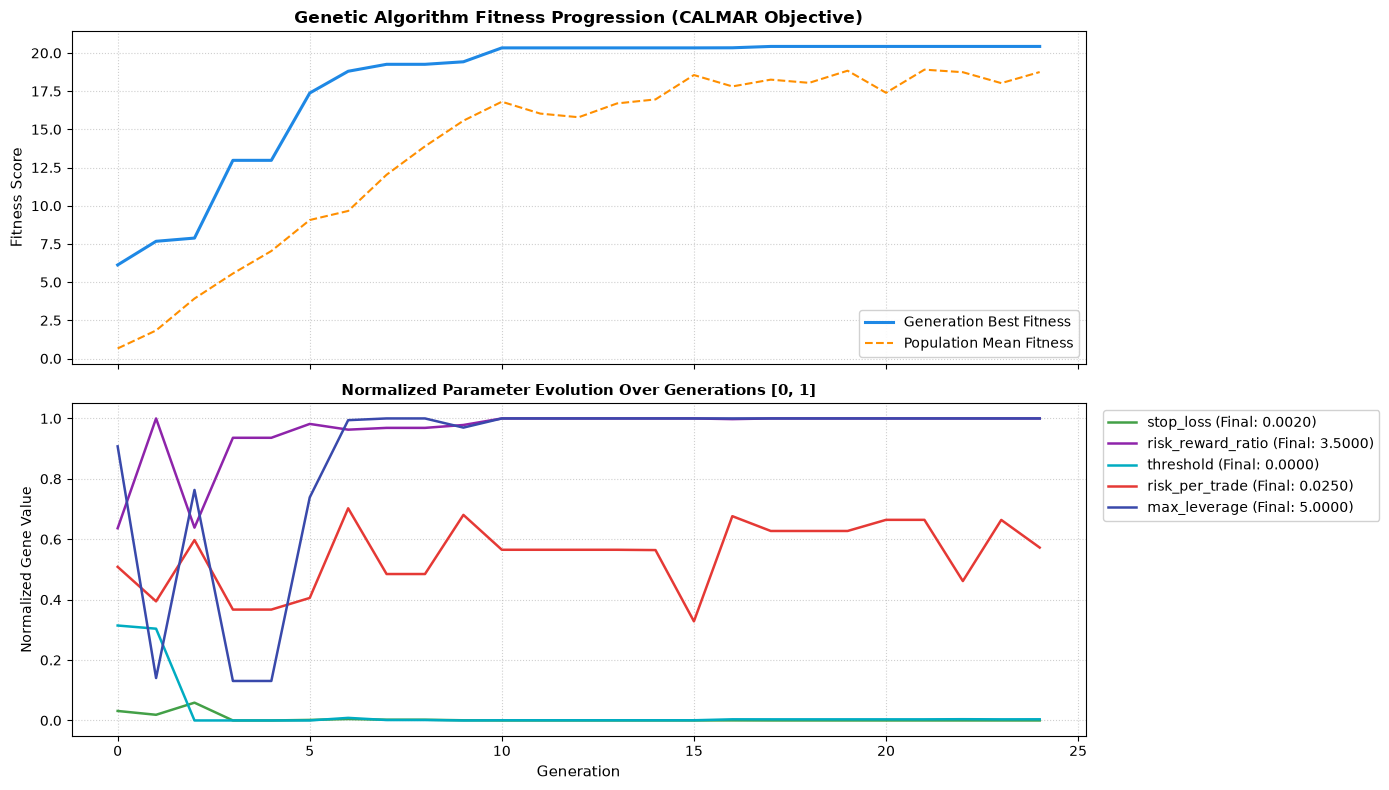

           INSTITUTIONAL QUANT TRADING PERFORMANCE REPORT
CAPITAL & RETURNS:
  Initial Capital        : $10,000.00
  Final Portfolio Value  : $163,531.64
  Strategy Net Return    : +1535.32%
  Benchmark (Buy & Hold) : -9.80%
  Strategy Alpha         : +1545.11%
  Annualized CAGR        : +181.67%
--------------------------------------------------------------------------------
TRADE EXECUTION & WIN/LOSS METRICS:
  Total Trades Executed  : 675 (Long: 382, Short: 293, Neutral: 5)
  Winning Trades         : 333 (49.33%)
  Losing Trades          : 342 (50.67%)
  Average Win ($)        : $951.94
  Average Loss ($)       : $477.96
  Realized Risk/Reward   : 1.99
  Gross Profit           : $316,994.56
  Gross Loss             : $163,462.92
  Profit Factor          : 1.94
  Trade Expectancy       : $227.45 per trade
--------------------------------------------------------------------------------
RISK-ADJUSTED METRICS:
  Max Drawdown           : -8.89%
  Annualized Sharpe      : 4.34
  Annualize

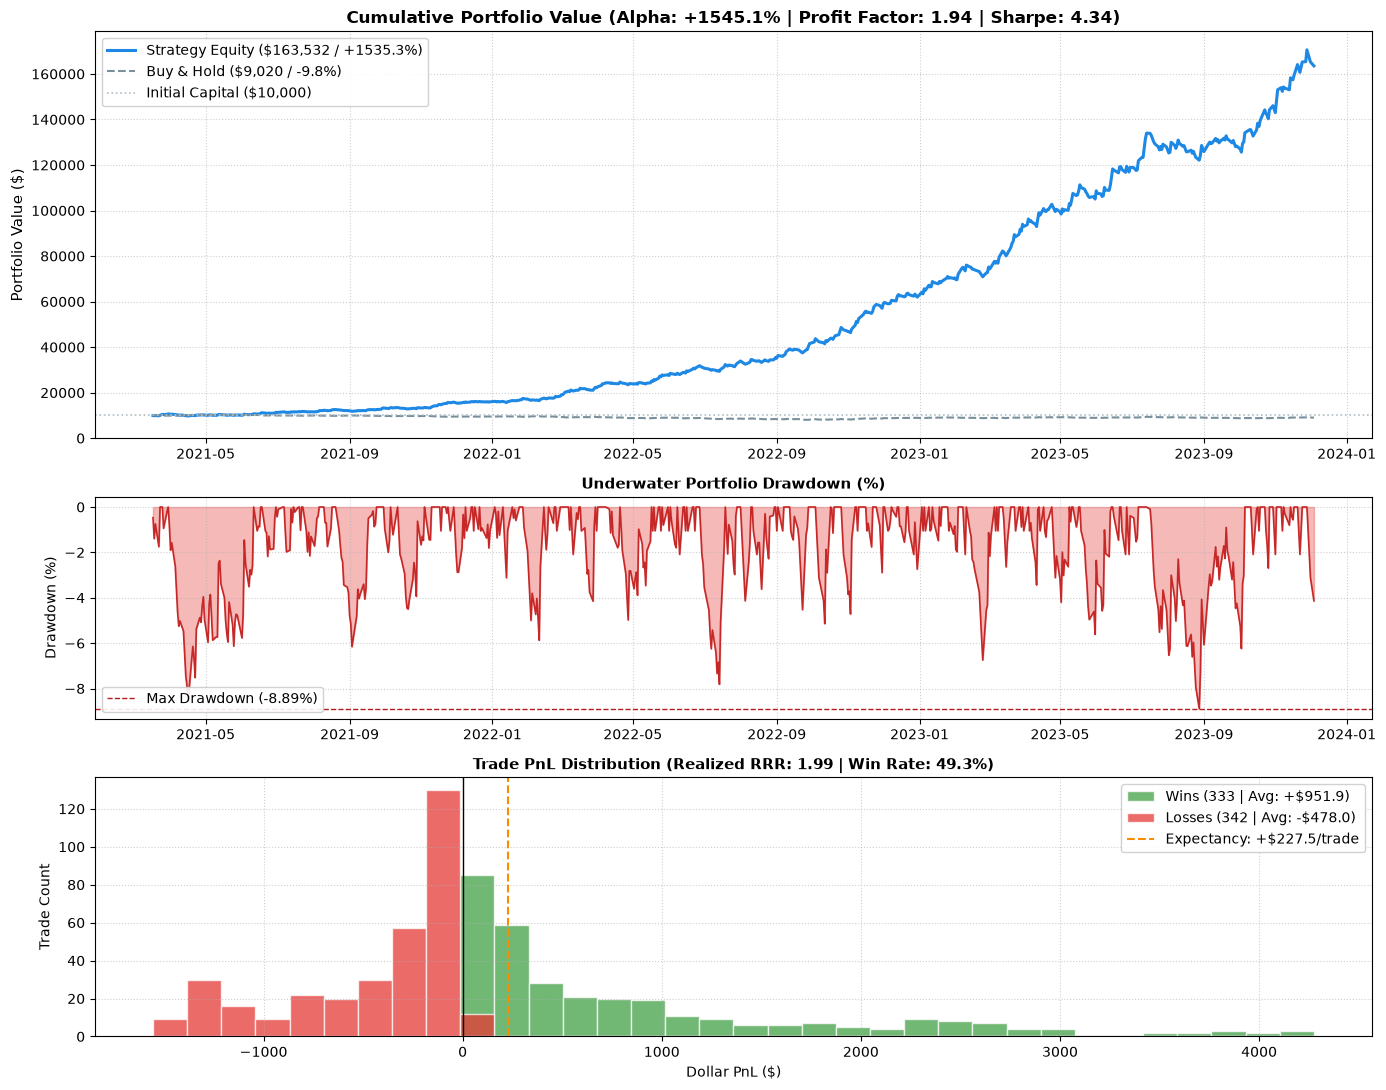

In [45]:
from utils import optimize_strategy_ga

# 1. Run the Genetic Algorithm on Validation Set predictions
val_preds = eur_lstm_eval_results["validation"]["predictions"]
val_targets = eur_lstm_eval_results["validation"]["targets"]
val_dates = eur_lstm_eval_results["validation"]["dates"]

ga_result = optimize_strategy_ga(
    predictions=val_preds,
    actual_returns=val_targets,
    fitness_metric="calmar",  # 'composite', 'sharpe', 'sortino', 'calmar', or 'profit_factor'
    population_size=40,          # 40 strategy candidates per generation
    generations=25,              # 25 evolutionary cycles
    fee_per_trade=0.0001,        # 1-pip transaction cost
    dates=val_dates,
    random_state=42,
    verbose=True,
)

# 2. View the GA convergence trajectories over generations
ga_result["optimizer"].plot_convergence()

# 3. View the best-evolved strategy performance & chart
best_calculator = ga_result["best_calculator"]
best_calculator.summary()
best_calculator.plot()

### TESTING GA RESULTS ON TEST DATA

           INSTITUTIONAL QUANT TRADING PERFORMANCE REPORT
CAPITAL & RETURNS:
  Initial Capital        : $10,000.00
  Final Portfolio Value  : $61,858.97
  Strategy Net Return    : +518.59%
  Benchmark (Buy & Hold) : +6.99%
  Strategy Alpha         : +511.60%
  Annualized CAGR        : +96.27%
--------------------------------------------------------------------------------
TRADE EXECUTION & WIN/LOSS METRICS:
  Total Trades Executed  : 650 (Long: 601, Short: 49, Neutral: 31)
  Winning Trades         : 324 (49.85%)
  Losing Trades          : 326 (50.15%)
  Average Win ($)        : $423.32
  Average Loss ($)       : $261.64
  Realized Risk/Reward   : 1.62
  Gross Profit           : $137,154.82
  Gross Loss             : $85,295.85
  Profit Factor          : 1.61
  Trade Expectancy       : $79.78 per trade
--------------------------------------------------------------------------------
RISK-ADJUSTED METRICS:
  Max Drawdown           : -9.73%
  Annualized Sharpe      : 3.27
  Annualized Sort

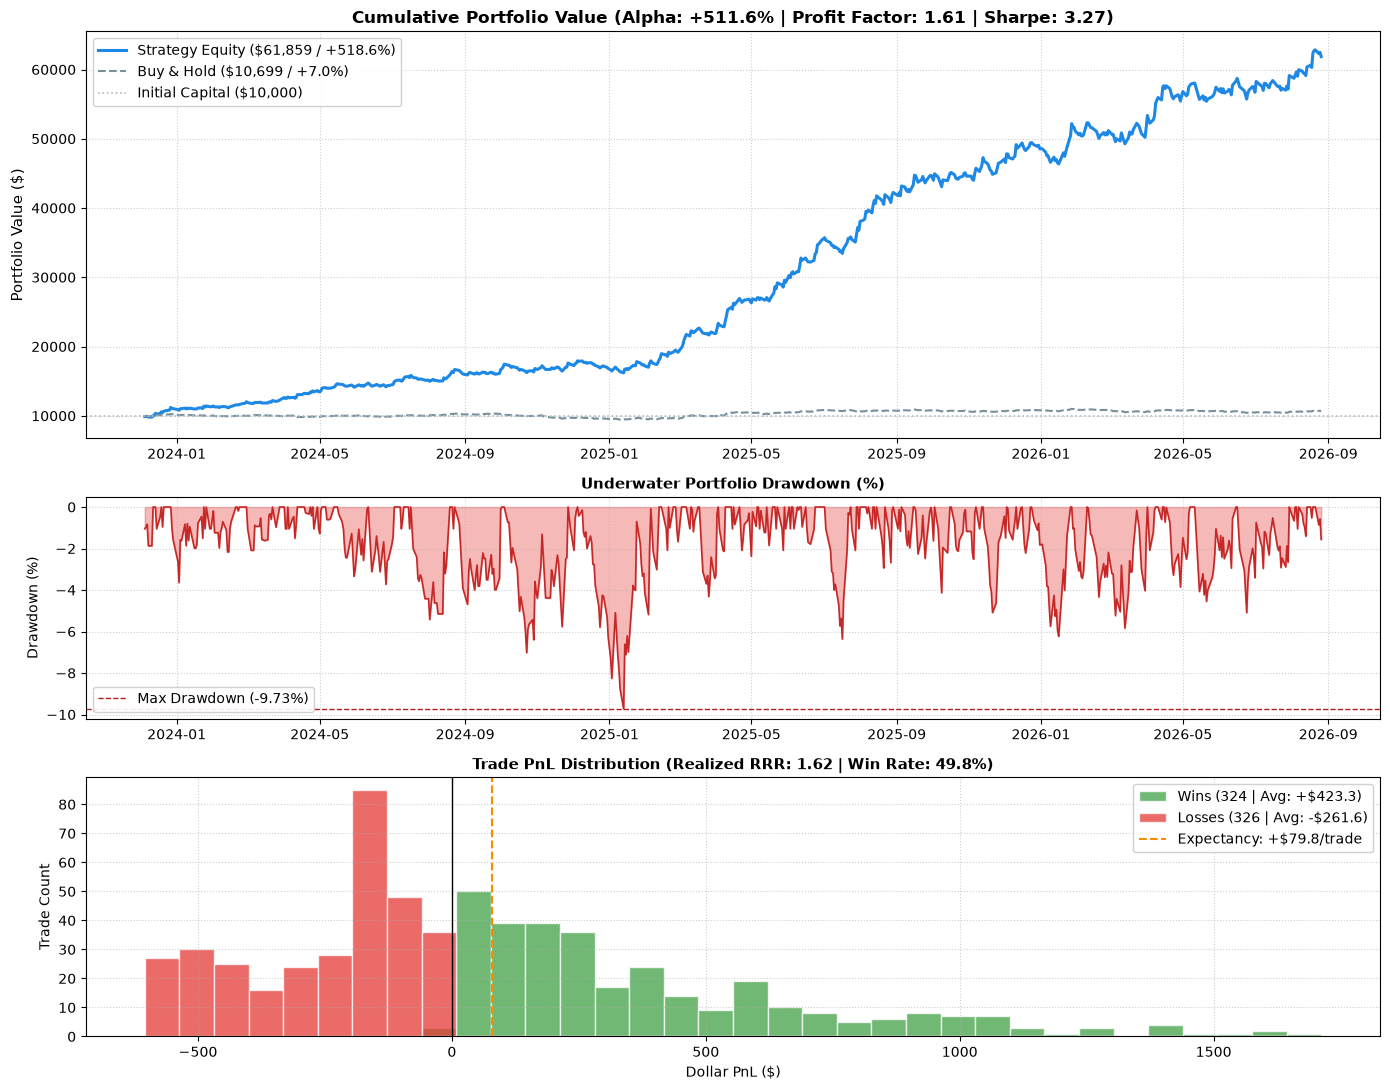

In [46]:
# 1. Instantiate the quantitative backtester
# You can test on "validation" or "test"

# Optimal Parameters:
#   stop_loss         : 0.00200 (0.200%)
#   risk_reward_ratio : 3.50
#   threshold         : 0.00004 (0.004%)
#   risk_per_trade    : 0.02746 (2.746%)
#   max_leverage      : 5.00
#   take_profit       : 0.00700 (0.700%)
split = "test"

calculator = AdvancedProfitCalculator(
    predictions=eur_lstm_eval_results[split]["predictions"],
    actual_returns=eur_lstm_eval_results[split]["targets"],
    initial_capital=10000.0,
    stop_loss=0.00200,         # 0.200% Stop Loss
    risk_reward_ratio=3.50,   # 1:3.5 RRR -> Auto-sets Take Profit to 0.700%
    threshold=0.00004,        # 0.004% deadzone filter (avoids noise below 0.004%)
    fee_per_trade=0.0001,    # 1-pip round-trip transaction friction
    risk_per_trade=0.02746,     # Risk exactly 2% of portfolio equity per trade
    max_leverage=5.00,        # Conservative 3x forex leverage cap
    dates=eur_lstm_eval_results[split]["dates"],
    take_profit=0.00700,       # 0.700% Take Profit (auto-calculated from RRR, but can be overridden here)
)

# 2. Print institutional performance summary
calculator.summary()

# 3. Render 3-panel quant trading dashboard:
#    - Panel 1: Portfolio Equity Curve vs Buy & Hold Benchmark
#    - Panel 2: Underwater Drawdown Curve (%)
#    - Panel 3: Trade PnL Distribution (Histogram of Wins & Losses)
calculator.plot()

### TRAINING FOR VAL ALSO

In [47]:
import torch
from torch.utils.data import DataLoader
from utils import train_on_val_data, train_torch_model_with_val_data

# Note: The functions `train_on_val_data` and `train_torch_model_with_val_data`
# are defined in utils.py and imported above. Below is the standalone definition
# for reference and direct customization:

def train_on_val_data(
    model,
    val_loader,
    loss_function,
    optimizer=None,
    epochs=15,
    lr=1e-4,
    device=None,
    log_every=5,
    scheduler=None,
    clip_grad_norm=None,
    shuffle=True,
):
    """
    Train / fine-tune a model on the validation data split.
    
    In financial time-series forecasting, models are initially trained on the training
    split and evaluated/tuned on the validation split. Before predicting on the test set,
    continuing training on the validation set adapts the model's parameters and internal
    states to the market regime immediately preceding the test period.
    
    Parameters
    ----------
    model : torch.nn.Module
        The PyTorch model to train (e.g. LSTMForecaster).
    val_loader : torch.utils.data.DataLoader or dict
        DataLoader containing validation batches, or a dict containing a 'val_loader' key.
    loss_function : callable
        Loss function (e.g., BigMoveAwareLoss or nn.MSELoss).
    optimizer : torch.optim.Optimizer, optional
        Optimizer for training. If None, an Adam optimizer with weight_decay=1e-5
        and learning rate `lr` is automatically instantiated.
    epochs : int, default=15
        Number of epochs to train on the validation data.
    lr : float, default=1e-4
        Learning rate if optimizer is not provided. Defaults to 1e-4 (fine-tuning rate).
    device : torch.device or str, optional
        Target device (CPU or CUDA). Defaults to model device or CUDA if available.
    log_every : int, default=5
        Frequency (in epochs) to print the average epoch loss. Set to 0 to disable.
    scheduler : torch.optim.lr_scheduler, optional
        Optional learning rate scheduler stepped after each epoch.
    clip_grad_norm : float, optional
        If specified, gradients are clipped to this maximum norm.
    shuffle : bool, default=True
        Whether to shuffle validation batches during training for improved gradient variance.
        
    Returns
    -------
    dict
        Dictionary containing:
        - 'val_train_losses': list of average training losses per epoch on the validation data.
    """
    if isinstance(val_loader, dict):
        if "val_loader" in val_loader:
            val_loader = val_loader["val_loader"]
        elif "validation" in val_loader:
            val_loader = val_loader["validation"]
        else:
            raise KeyError("val_loader dict must contain 'val_loader' or 'validation' key.")

    if val_loader is None or len(val_loader) == 0:
        raise ValueError("val_loader is empty or None.")

    target_device = device or (
        next(model.parameters()).device
        if list(model.parameters())
        else (torch.device("cuda" if torch.cuda.is_available() else "cpu"))
    )
    model.to(target_device)

    if optimizer is None:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)

    loader_to_use = val_loader
    if shuffle and hasattr(val_loader, "dataset") and val_loader.dataset is not None:
        batch_size = getattr(val_loader, "batch_size", 32)
        loader_to_use = DataLoader(
            val_loader.dataset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=getattr(val_loader, "num_workers", 0),
            pin_memory=getattr(val_loader, "pin_memory", False),
        )

    val_train_losses = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        num_batches = 0

        for batch_x, batch_y in loader_to_use:
            batch_x = batch_x.to(target_device)
            batch_y = batch_y.to(target_device)

            optimizer.zero_grad()
            predictions = model(batch_x)
            if predictions.shape != batch_y.shape:
                if predictions.ndim == 2 and predictions.shape[1] == 1 and batch_y.ndim == 1:
                    predictions = predictions.squeeze(1)
                elif batch_y.ndim == 2 and batch_y.shape[1] == 1 and predictions.ndim == 1:
                    predictions = predictions.unsqueeze(1)

            loss = loss_function(predictions, batch_y)
            loss.backward()

            if clip_grad_norm is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad_norm)

            optimizer.step()

            running_loss += loss.item()
            num_batches += 1

        epoch_loss = running_loss / max(num_batches, 1)
        val_train_losses.append(epoch_loss)

        if scheduler is not None:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(epoch_loss)
            else:
                scheduler.step()

        if log_every and (epoch + 1) % log_every == 0:
            print(f"Val Training Epoch {epoch + 1}/{epochs} - Loss: {epoch_loss:.5f}")

    return {
        "val_train_losses": val_train_losses,
    }


In [48]:
# ────────────────────────────────────────────────────────────────────────────
# Train eur_lstm_model on the validation data split
# ────────────────────────────────────────────────────────────────────────────
val_history = train_on_val_data(
    model=eur_lstm_model,
    val_loader=eur_lstm_loaders["val_loader"],
    loss_function=eur_lstm_loss_fn,
    epochs=15,             # 15 fine-tuning epochs on validation data
    lr=1e-4,              # Slightly lower learning rate for stable fine-tuning
    device=DEVICE,
    log_every=5,
    shuffle=True,
)


Val Training Epoch 5/15 - Loss: 4.47239
Val Training Epoch 10/15 - Loss: 4.18426
Val Training Epoch 15/15 - Loss: 4.37771


In [49]:
# ────────────────────────────────────────────────────────────────────────────
# Re-evaluate model on test data after training on validation set
# ────────────────────────────────────────────────────────────────────────────
eur_lstm_eval_results_val_trained = predict_and_store_window_model(
    model=eur_lstm_model,
    model_name="EUR LSTM + Val Training (Directional)",
    loaders_dict=eur_lstm_loaders,
    model_results=model_results,
    device=DEVICE,
    output_path=str(RESULTS_PATH),
    metadata={"window_size": LSTM_WINDOW_SIZE, "target": "EUR_Log_Returns", "trained_on_val": True},
    price_data=eur_df,
    price_column="EUR",
)

# Compare Test metrics before vs after training on val data
print("\n=== Test Metrics Comparison: Before vs After Validation Training ===")
m_before = eur_lstm_eval_results["test"]["metrics"]
m_after = eur_lstm_eval_results_val_trained["test"]["metrics"]
print(f"MAE          : {m_before['mae']:.5f}  ->  {m_after['mae']:.5f}")
print(f"RMSE         : {m_before['rmse']:.5f}  ->  {m_after['rmse']:.5f}")
print(f"Dir. Accuracy: {m_before['directional_accuracy']:.2f}%  ->  {m_after['directional_accuracy']:.2f}%")



=== Test Metrics Comparison: Before vs After Validation Training ===
MAE          : 0.00310  ->  0.00310
RMSE         : 0.00423  ->  0.00422
Dir. Accuracy: 75.59%  ->  76.03%


           INSTITUTIONAL QUANT TRADING PERFORMANCE REPORT
CAPITAL & RETURNS:
  Initial Capital        : $10,000.00
  Final Portfolio Value  : $78,460.42
  Strategy Net Return    : +684.60%
  Benchmark (Buy & Hold) : +6.99%
  Strategy Alpha         : +677.61%
  Annualized CAGR        : +114.32%
--------------------------------------------------------------------------------
TRADE EXECUTION & WIN/LOSS METRICS:
  Total Trades Executed  : 647 (Long: 507, Short: 140, Neutral: 34)
  Winning Trades         : 333 (51.47%)
  Losing Trades          : 314 (48.53%)
  Average Win ($)        : $481.26
  Average Loss ($)       : $292.35
  Realized Risk/Reward   : 1.65
  Gross Profit           : $160,258.67
  Gross Loss             : $91,798.25
  Profit Factor          : 1.75
  Trade Expectancy       : $105.81 per trade
--------------------------------------------------------------------------------
RISK-ADJUSTED METRICS:
  Max Drawdown           : -7.16%
  Annualized Sharpe      : 3.68
  Annualized S

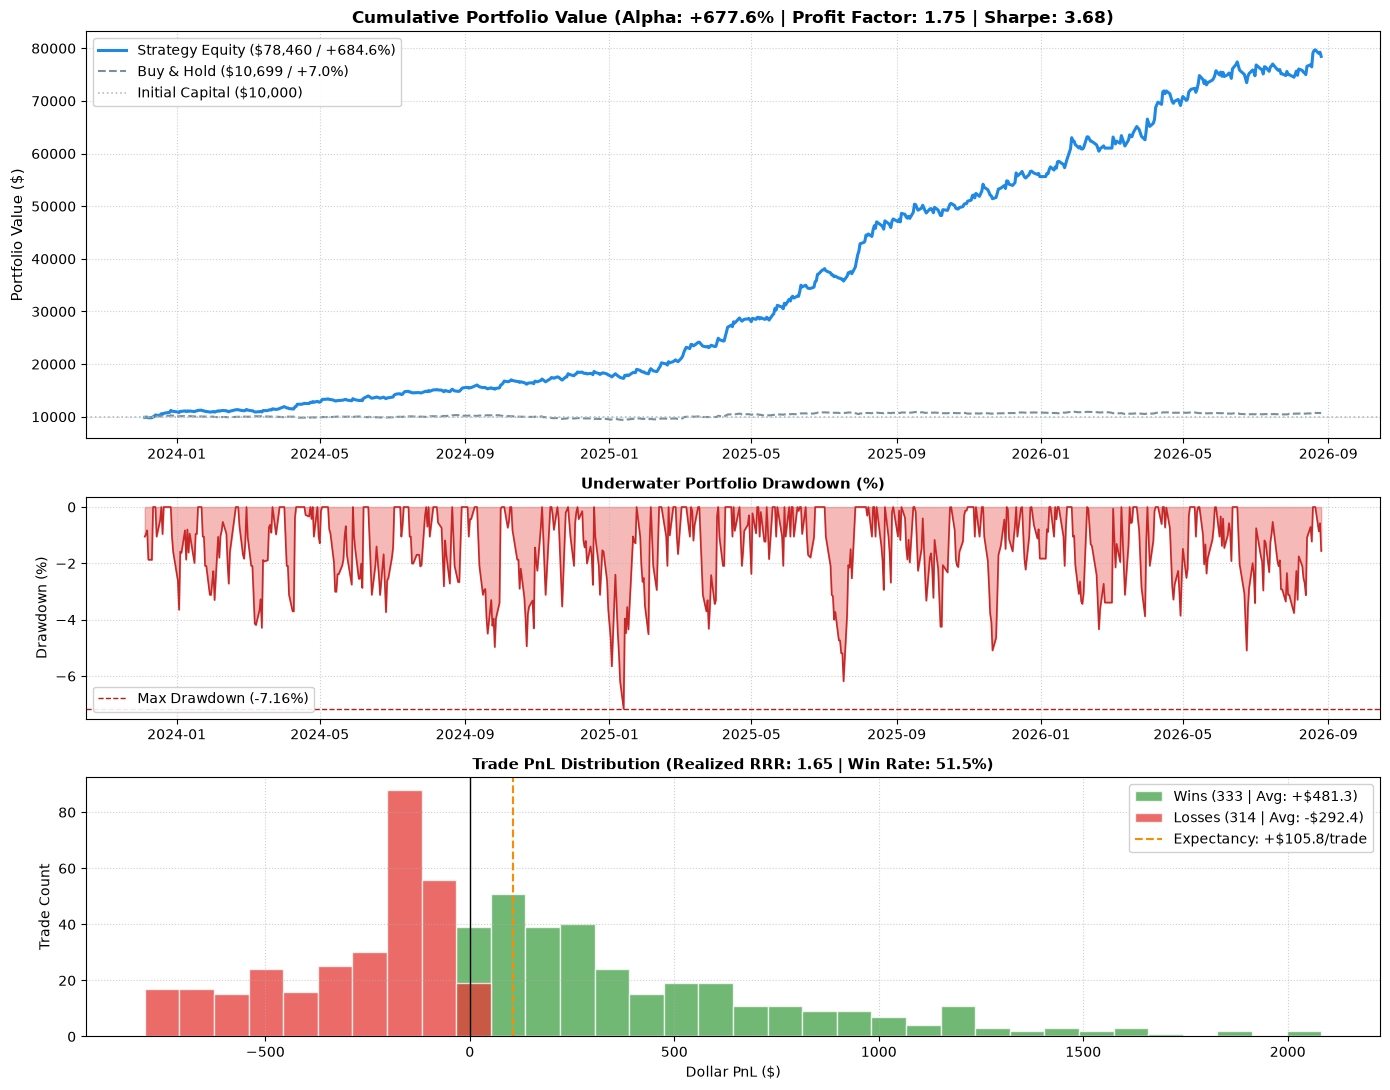

In [50]:
# ────────────────────────────────────────────────────────────────────────────
# Backtest using GA optimal parameters on updated Test predictions
# ────────────────────────────────────────────────────────────────────────────
split = "test"

calculator_val_trained = AdvancedProfitCalculator(
    predictions=eur_lstm_eval_results_val_trained[split]["predictions"],
    actual_returns=eur_lstm_eval_results_val_trained[split]["targets"],
    initial_capital=10000.0,
    stop_loss=0.00200,         # 0.200% Stop Loss from GA
    risk_reward_ratio=3.50,   # 1:3.5 RRR from GA
    threshold=0.00004,        # 0.004% deadzone filter from GA
    fee_per_trade=0.0001,    # 1-pip transaction friction
    risk_per_trade=0.02746,     # 2.746% risk per trade from GA
    max_leverage=5.00,        # 5x leverage cap from GA
    dates=eur_lstm_eval_results_val_trained[split]["dates"],
    take_profit=0.00700,       # 0.700% Take Profit
)

# Institutional performance summary & 3-panel dashboard
calculator_val_trained.summary()
calculator_val_trained.plot()


In [51]:
from utils import train_on_val_data


val_history = train_on_val_data(
    model=eur_lstm_model,
    val_loader=eur_lstm_loaders["val_loader"],
    loss_function=eur_lstm_loss_fn,
    epochs=15,             # 15 fine-tuning epochs on validation data
    lr=1e-4,              # Slightly lower learning rate for stable fine-tuning
    device=DEVICE,
    log_every=5,
    shuffle=True,
)

Val Training Epoch 5/15 - Loss: 4.17091
Val Training Epoch 10/15 - Loss: 4.19305
Val Training Epoch 15/15 - Loss: 4.43198


In [52]:
eur_lstm_eval_results_val_trained = predict_and_store_window_model(
    model=eur_lstm_model,
    model_name="EUR LSTM + Val Training (Directional)",
    loaders_dict=eur_lstm_loaders,
    model_results=model_results,
    device=DEVICE,
    output_path=str(RESULTS_PATH),
    metadata={"window_size": LSTM_WINDOW_SIZE, "target": "EUR_Log_Returns", "trained_on_val": True},
    price_data=eur_df,
    price_column="EUR",
)

# Compare Test metrics before vs after training on val data
print("\n=== Test Metrics Comparison: Before vs After Validation Training ===")
m_before = eur_lstm_eval_results["test"]["metrics"]
m_after = eur_lstm_eval_results_val_trained["test"]["metrics"]
print(f"MAE          : {m_before['mae']:.5f}  ->  {m_after['mae']:.5f}")
print(f"RMSE         : {m_before['rmse']:.5f}  ->  {m_after['rmse']:.5f}")
print(f"Dir. Accuracy: {m_before['directional_accuracy']:.2f}%  ->  {m_after['directional_accuracy']:.2f}%")


=== Test Metrics Comparison: Before vs After Validation Training ===
MAE          : 0.00310  ->  0.00310
RMSE         : 0.00423  ->  0.00423
Dir. Accuracy: 75.59%  ->  75.74%


           INSTITUTIONAL QUANT TRADING PERFORMANCE REPORT
CAPITAL & RETURNS:
  Initial Capital        : $10,000.00
  Final Portfolio Value  : $80,439.08
  Strategy Net Return    : +704.39%
  Benchmark (Buy & Hold) : +6.99%
  Strategy Alpha         : +697.40%
  Annualized CAGR        : +116.30%
--------------------------------------------------------------------------------
TRADE EXECUTION & WIN/LOSS METRICS:
  Total Trades Executed  : 636 (Long: 468, Short: 168, Neutral: 45)
  Winning Trades         : 328 (51.57%)
  Losing Trades          : 308 (48.43%)
  Average Win ($)        : $487.17
  Average Loss ($)       : $290.11
  Realized Risk/Reward   : 1.68
  Gross Profit           : $159,791.60
  Gross Loss             : $89,352.52
  Profit Factor          : 1.79
  Trade Expectancy       : $110.75 per trade
--------------------------------------------------------------------------------
RISK-ADJUSTED METRICS:
  Max Drawdown           : -6.29%
  Annualized Sharpe      : 3.73
  Annualized S

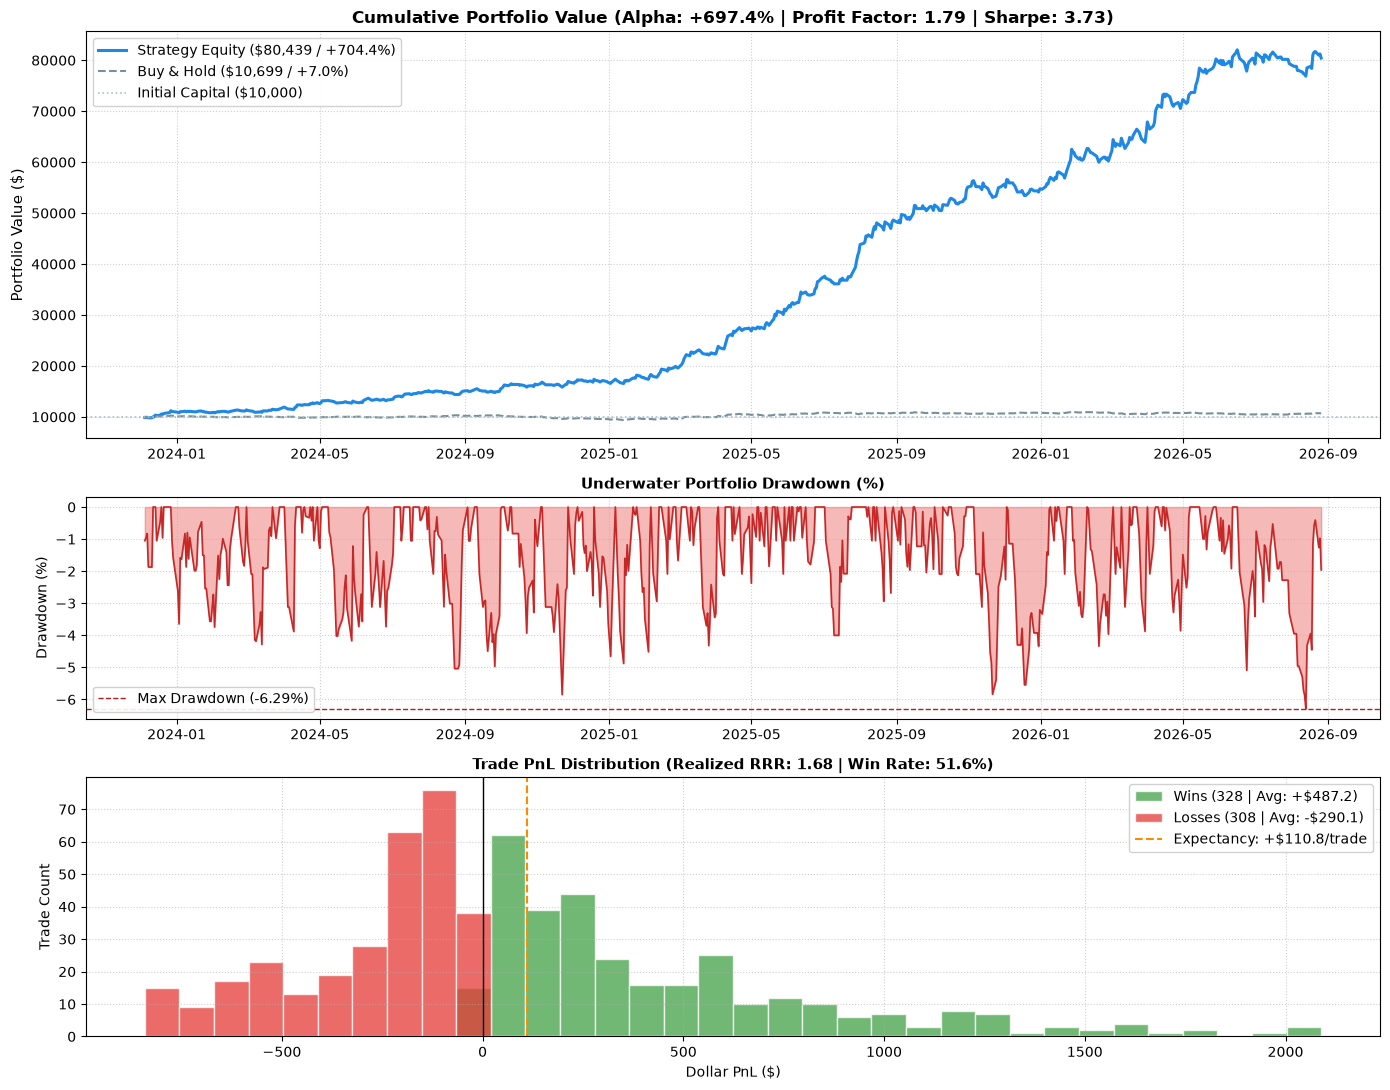

In [53]:
split = "test"

calculator_val_trained = AdvancedProfitCalculator(
    predictions=eur_lstm_eval_results_val_trained[split]["predictions"],
    actual_returns=eur_lstm_eval_results_val_trained[split]["targets"],
    initial_capital=10000.0,
    stop_loss=0.00200,         # 0.200% Stop Loss from GA
    risk_reward_ratio=3.50,   # 1:3.5 RRR from GA
    threshold=0.00004,        # 0.004% deadzone filter from GA
    fee_per_trade=0.0001,    # 1-pip transaction friction
    risk_per_trade=0.02746,     # 2.746% risk per trade from GA
    max_leverage=5.00,        # 5x leverage cap from GA
    dates=eur_lstm_eval_results_val_trained[split]["dates"],
    take_profit=0.00700,       # 0.700% Take Profit
)

calculator_val_trained.summary()
calculator_val_trained.plot()

### EXPORTING THE MODEL (TRAINED TILL TEST DATA / ANY SPECIFIED SPLIT)

In algorithmic trading and production pipelines:
1. **Model Fine-Tuning**: You can fine-tune the model up through any split (`train`, `val`, or `test`) using `train_on_split(...)`. Training up through the test set prepares the model for real-time live trading on incoming future market ticks.
2. **Comprehensive Checkpointing**: `export_model(...)` packages the model weights alongside the exact `feature_scaler`, `target_scaler`, `feature_columns`, sequence `window_size`, architecture hyperparameters, and metadata needed to reproduce inferences anywhere.


In [54]:
from utils import export_model, load_model, train_on_split

# ────────────────────────────────────────────────────────────────────────
# 1. (Optional) Fine-tune model till the test data split
# ────────────────────────────────────────────────────────────────────────
# In live algorithmic trading, after validating performance on test data,
# the network can be updated on test data to capture the most recent market regime.
test_history = train_on_split(
    model=eur_lstm_model,
    dataloader=eur_lstm_loaders["test_loader"],
    loss_function=eur_lstm_loss_fn,
    epochs=10,             # Fine-tuning epochs on test data
    lr=1e-4,              # Low learning rate to preserve learned representations
    device=DEVICE,
    log_every=5,
    shuffle=True,
    split_name="test",
)

# ────────────────────────────────────────────────────────────────────────
# 2. Export the model checkpoint (weights + scalers + metadata)
# ────────────────────────────────────────────────────────────────────────
export_path = "models/eur_lstm_final.pt"

# You can specify trained_till as 'test', 'val', or 'train' based on your workflow
exported_file = export_model(
    model=eur_lstm_model,
    filepath=export_path,
    trained_till="test",    # Split milestone reached: 'train', 'val', or 'test'
    loaders_dict=eur_lstm_loaders,
    metadata={
        "target": "EUR",
        "description": "EUR/USD LSTM forecaster trained through test data with Directional BigMoveAwareLoss",
        "ga_optimal_params": {
            "stop_loss": 0.00200,
            "risk_reward_ratio": 3.50,
            "threshold": 0.00004,
            "risk_per_trade": 0.02746,
            "max_leverage": 5.00,
            "take_profit": 0.00700,
        },
    },
)


[Test Training] Epoch 5/10 - Loss: 2.86285
[Test Training] Epoch 10/10 - Loss: 2.72651
Model successfully exported to: C:\Users\xprin\Desktop\AIML\BTP\models\eur_lstm_final.pt
  Trained Till   : test
  Architecture   : LSTMForecaster ({'input_size': 23, 'hidden_size': 32, 'num_layers': 1, 'dropout': 0.0, 'output_size': 1})
  Features (23) : ['EUR', 'INR', 'JPY', 'FFER', 'US10YY']...
  Target         : Log_Returns
  Window Size    : 10


### LOADING AND INFERENCE DEMO (`load_model`)

Using `load_model(filepath, device=DEVICE)` from `utils.py`:
- Restores the exact model architecture and trained weights in evaluation mode.
- Automatically extracts the fitted `feature_scaler` and `target_scaler`.
- Provides an immediate `.predict()` helper that accepts raw market data (DataFrames or arrays), performs scaling, runs forward pass, and denormalizes output returns back to actual percentage returns.


In [55]:
# ────────────────────────────────────────────────────────────────────────
# 3. Load the exported model back into memory
# ────────────────────────────────────────────────────────────────────────
loaded_bundle = load_model(export_path, device=DEVICE)

print("\nLoaded Model Details:")
print(f"  Trained Till    : {loaded_bundle['trained_till']}")
print(f"  Features Count  : {len(loaded_bundle['feature_columns'])}")
print(f"  Lookback Window : {loaded_bundle['window_size']}")
print(f"  Exported At     : {loaded_bundle['exported_at']}")

# ────────────────────────────────────────────────────────────────────────
# 4. Run sample inference using the attached predict() helper
# ────────────────────────────────────────────────────────────────────────
# Pass raw, unscaled feature window directly from eur_df
window_size = loaded_bundle["window_size"]
sample_raw_features = eur_df[loaded_bundle["feature_columns"]].iloc[-window_size:]

predicted_log_return = loaded_bundle["predict"](sample_raw_features)
current_price = eur_df["EUR"].iloc[-1]
predicted_next_price = current_price * np.exp(predicted_log_return)

print(f"\nLive Inference Verification:")
print(f"  Current EUR Price       : {current_price:.5f}")
print(f"  Predicted Next Return   : {predicted_log_return:+.5f} ({predicted_log_return * 100:+.3f}%)")
print(f"  Predicted Next Price    : {predicted_next_price:.5f}")


Model successfully loaded from: eur_lstm_final.pt
  Trained Till : test
  Target       : Log_Returns
  Device       : cuda
  Window Size  : 10

Loaded Model Details:
  Trained Till    : test
  Features Count  : 23
  Lookback Window : 10
  Exported At     : 2026-10-24T12:45:58.183374

Live Inference Verification:
  Current EUR Price       : 1.16510
  Predicted Next Return   : +0.00016 (+0.016%)
  Predicted Next Price    : 1.16529
